---
**Script name:** 04_02_01_01_window_size_030.ipynb

**Purpose of script:** This script uses data from 3 different nodes to simulate the error and to test different window sizes to compare the KL divergence and for correcting the corrupted timestamps. This was repeated with a 30 minutes, 1 hour and 2 hour window size and additionally tested different cut off values for the KL divergence score.

**Author:** Dr Katie Allan

**Date Created:** 2022-07-10

**Email:** katie.allan@sussex.ac.uk

**License:** 

---

**Notes:** Change 'path_to_folder' to appropriate folder paths.

---

## Importing libraries that are required

In [ ]:
import time
from datetime import timedelta
from scipy.special import rel_entr
from scipy.stats import entropy
import pickle
import pandas as pd
import numpy as np
import os
from pathlib import Path
from dask import delayed, compute
from dask.distributed import Client
from plotnine import (
    ggplot,
    aes,
    geom_histogram,
    geom_point,
    theme_matplotlib,
    theme_set,
)

## Functions that are used throughout the script

In [4]:
#Function to resample the time intervals of a dataframe
def resample_time_shifts(df, shift_seconds, total_shifts):
    df.set_index(['time'], inplace=True)
    offset_dfs = []

    for shift in range(total_shifts):
        offset = pd.Timedelta(seconds = shift_seconds * shift)

        resampled = df.resample('30min', origin='epoch', offset=offset)['id'].value_counts().reset_index()
        offset_df = resampled.pivot(index='time', columns='id', values='count').fillna(0)
        offset_df = offset_df.reindex(columns=all_tag_ids, fill_value = 0)

        offset_dfs.append(offset_df)
    
    return offset_dfs

In [5]:
#function to normalize each row of data
def normalize_df_rows(df):
    return df.div(df.sum(axis=1), axis=0)

In [6]:
#calculate KL divergence between each row of two dataframes
def calc_non_inf_kl_divs(anchor_df, shifted_test_df):
    non_inf_results = []
    # entropy_matrix = np.zeros((len(anchor_df), len(shifted_test_df)))
    for i, rowI in enumerate(anchor_df.values):
        anchor_time = anchor_df.index[i]

        for j, rowJ in enumerate(shifted_test_df.values):
            test_time = shifted_test_df.index[j]

            time_delta = anchor_time - test_time

            ent = (entropy(rowI, rowJ))
            # entropy_matrix[i, j] = ent

            if not np.isinf(ent):
                non_inf_result = {'anchor_time': anchor_time,
                                  'test_time': test_time,
                                  'time_diff': time_delta,
                                  'kl_div': ent}
                
                non_inf_results.append(non_inf_result)
    return non_inf_results

In [7]:
#calculate kl divergence of shifted dataframe
def calc_all_non_inf_kl_divs(anchor_df, shifted_test_dfs):
    results = []
    for shift in range(len(shifted_test_dfs)):
        print(f'Shift {shift}')
        results += calc_non_inf_kl_divs(anchor_df, shifted_test_dfs[shift])
    return pd.DataFrame(results)

In [ ]:
# designing functions to filter each node group to only keep data within plausible time range, based on deployment times
def filter_expressway_1(group):
    return group.loc['2023-09-23 18:17:47' : '2023-10-31 10:41:29']

def filter_expressway_2(group):
    return group.loc['2023-11-07 14:05:28' : '2023-11-24 07:07:39']

def filter_kilnwood(group):
    return group.loc['2023-09-26 18:50:30' : '2024-01-18 16:26:41']

def filter_bathouse_1(group):
    return group.loc['2023-09-20 13:47:53' : '2023-11-24 15:30:15']

def filter_bathouse_2(group):
    return group.loc['2023-12-01 17:22:37' : '2024-01-22 18:18:02']
    

## Connect to Dask cluster for parallel processing

In [3]:
client = Client()
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 4
Total threads: 8,Total memory: 15.36 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:58765,Workers: 4
Dashboard: http://127.0.0.1:8787/status,Total threads: 8
Started: Just now,Total memory: 15.36 GiB
Comm: tcp://127.0.0.1:58791,Total threads: 2
Dashboard: http://127.0.0.1:58792/status,Memory: 3.84 GiB
Nanny: tcp://127.0.0.1:58769,


## Define variables

In [2]:
#set the time and repeats for the script
shift_seconds = 10
total_shifts = 180

In [ ]:
# File directories
input_dir = Path("../../04_01_data_wrangling/output")
output_dir = Path(".")

## Load Data

In [ ]:
#check for pickle files, if they aren't in the directory create them
if not os.path.isfile(f'{output_dir}/bathouse_anchors_normalized.pickle') or not os.path.isfile(f'{output_dir}bathouse_mislabelled_normalized_shifts.pickle'):

    print('[[[ Loading Data ]]]')
    beforeLoadingData = time.time()
    with open(f'{input_dir}/correct_node_data.pickle', 'rb') as file:
        correct_dataframes = pickle.load(file)
    with open(f'{input_dir}/station_data.pickle', 'rb') as file:
        station_dataframes = pickle.load(file)
    with open(f'{input_dir}/incorrect_node_data.pickle', 'rb') as file:
        incorrect_dataframes = pickle.load(file)
    afterLoadingData = time.time()
    print(f'{afterLoadingData - beforeLoadingData:.2f}s')
    
    ##############

    print('[[[ Mangling data ]]]')
    beforeMangling = time.time()
    all_tag_ids = ['55331961','4B551E4B', '78780778', '4C785261', '2D661E19', '33333433', '78341E61', '52616161', '662A6107', '614B2A61', '34332A07', '612A4C1E', '2D2D612A', '2D2A7852', '07071E19', '2D192D78', '1E4B074C', '4B662A33', '19557855', '2A615252', '33663378', '5561331E', '341E4B2A', '1978782D', '2D344B2D', '19616666', '551E3307', '34783378', '66667833', '4B616652', '4C610761', '33331E55', '612A3355', '4B2D664C']

    # Correct data for anchors
    bathouse_anchors_raw = {
        "ExpressWay_1": correct_dataframes['node_376adf_beep_3_correct'],
        "ExpressWay_2": correct_dataframes['node_376adf_beep_4_correct'],
        "BatHouse_1": correct_dataframes['node_3795d0_beep_2_correct'],
        "BatHouse_2": correct_dataframes['node_3795d0_beep_3_correct'],
        "KilnWood": correct_dataframes['node_377401_beep_3_correct'],
        "Huxbear_Vineyard": station_dataframes['CFF730D7207F'],
        "Chudleigh": station_dataframes['V30B0154D392']
    }
    bathouse_anchors = {key: df.loc[(df['time'] >= '2023-09-19 00:00:00')][['time', 'id']] for key, df in bathouse_anchors_raw.items()}

    bathouse_anchors_normalized = {key: normalize_df_rows(resample_time_shifts(df,1,1)[0]) for key, df in bathouse_anchors.items()}

    #simulate the error in the timestamps
    bathouse_simulated_time_diff = {
        "ExpressWay_1": bathouse_anchors_raw['ExpressWay_1'],
        "ExpressWay_2": bathouse_anchors_raw['ExpressWay_2'],
        "BatHouse_1": bathouse_anchors_raw['BatHouse_1'],
        "BatHouse_2": bathouse_anchors_raw['BatHouse_2'],
        "KilnWood": bathouse_anchors_raw['KilnWood']
    }
    
    first_date = pd.Timestamp('2017-01-01 00:00:00')
    bathouse_simulated_time_diff = {key: df.assign(time = df['time'] - (df.iloc[0, 0] - first_date)) for key, df in bathouse_simulated_time_diff.items()}
    
    bathouse_simulated_time_diff_normalized_shifts = {key: list(map(normalize_df_rows, resample_time_shifts(df, shift_seconds, total_shifts))) for key, df in bathouse_simulated_time_diff.items()}

    afterMangling = time.time()
    print(f'{afterMangling - beforeMangling:.2f}s')

    ##############
    print('[[[ Writing data ]]]')
    beforeWriting = time.time()

    with open(f'{output_dir}/bathouse_anchors_normalized.pickle', 'wb') as handle:
        pickle.dump(bathouse_anchors_normalized, handle, protocol=pickle.HIGHEST_PROTOCOL)
    with open(f'{output_dir}/bathouse_simulated_time_diff_normalized_shifts.pickle', 'wb') as handle:
        pickle.dump(bathouse_simulated_time_diff_normalized_shifts, handle, protocol=pickle.HIGHEST_PROTOCOL)

    AfterWriting = time.time()
    print(f'{AfterWriting - beforeWriting:.2f}s')

else:
    print('[[[ Loading data ]]]')
    beforeLoadingData = time.time()

    with open(f'{output_dir}/bathouse_anchors_normalized.pickle', 'rb') as file:
        bathouse_anchors_normalized = pickle.load(file)
    with open(f'{output_dir}/bathouse_simulated_time_diff_normalized_shifts.pickle', 'rb') as file:
        bathouse_simulated_time_diff_normalized_shifts = pickle.load(file)

    afterLoadingData = time.time()
    print(f'{afterLoadingData - beforeLoadingData:.2f}s')

[[[ Loading Data ]]]
0.58s
[[[ Mangling data ]]]
7.00s
[[[ Writing data ]]]
0.51s


## Data processing

In [ ]:
#filter anchors to only keep data within plausible time range per node - group 1
ExpressWay_1_anchors = {key: filter_expressway_1(df) for key, df in bathouse_anchors_normalized.items()}
ExpressWay_2_anchors = {key: filter_expressway_2(df) for key, df in bathouse_anchors_normalized.items()}
KilnWood_anchors = {key: filter_kilnwood(df) for key, df in bathouse_anchors_normalized.items()}
BatHouse_1_anchors = {key: filter_bathouse_1(df) for key, df in bathouse_anchors_normalized.items()}
BatHouse_2_anchors = {key: filter_bathouse_2(df) for key, df in bathouse_anchors_normalized.items()}

In [11]:
# Remove the same dataframe from the anchors dictionary
if 'ExpressWay_1' in ExpressWay_1_anchors:
    del ExpressWay_1_anchors['ExpressWay_1']
if 'ExpressWay_2' in ExpressWay_2_anchors:
    del ExpressWay_2_anchors['ExpressWay_2']
if 'KilnWood' in KilnWood_anchors:
    del KilnWood_anchors['KilnWood']
if 'BatHouse_1' in BatHouse_1_anchors:
    del BatHouse_1_anchors['BatHouse_1']
if 'BatHouse_2' in BatHouse_2_anchors:
    del BatHouse_2_anchors['BatHouse_2']

In [12]:
# Remove empty dataframes from the dictionary
ExpressWay_1_anchors = {key: df for key, df in ExpressWay_1_anchors.items() if not df.empty}
ExpressWay_2_anchors = {key: df for key, df in ExpressWay_2_anchors.items() if not df.empty}
KilnWood_anchors = {key: df for key, df in KilnWood_anchors.items() if not df.empty}
BatHouse_1_anchors = {key: df for key, df in BatHouse_1_anchors.items() if not df.empty}
BatHouse_2_anchors = {key: df for key, df in BatHouse_2_anchors.items() if not df.empty}

In [13]:
#Calculate the KL Divergence of nodes
ExpressWay_1_kl_div = {key: calc_all_non_inf_kl_divs(df, bathouse_simulated_time_diff_normalized_shifts['ExpressWay_1']) for key, df in ExpressWay_1_anchors.items()}
ExpressWay_2_kl_div = {key: calc_all_non_inf_kl_divs(df, bathouse_simulated_time_diff_normalized_shifts['ExpressWay_2']) for key, df in ExpressWay_2_anchors.items()}
KilnWood_kl_div = {key: calc_all_non_inf_kl_divs(df, bathouse_simulated_time_diff_normalized_shifts['KilnWood']) for key, df in KilnWood_anchors.items()}
BatHouse_1_kl_div = {key: calc_all_non_inf_kl_divs(df, bathouse_simulated_time_diff_normalized_shifts['BatHouse_1']) for key, df in BatHouse_1_anchors.items()}
BatHouse_2_kl_div = {key: calc_all_non_inf_kl_divs(df, bathouse_simulated_time_diff_normalized_shifts['BatHouse_2']) for key, df in BatHouse_2_anchors.items()}

Shift 0
Shift 1
Shift 2
Shift 3
Shift 4
Shift 5
Shift 6
Shift 7
Shift 8
Shift 9
Shift 10
Shift 11
Shift 12
Shift 13
Shift 14
Shift 15
Shift 16
Shift 17
Shift 18
Shift 19
Shift 20
Shift 21
Shift 22
Shift 23
Shift 24
Shift 25
Shift 26
Shift 27
Shift 28
Shift 29
Shift 30
Shift 31
Shift 32
Shift 33
Shift 34
Shift 35
Shift 36
Shift 37
Shift 38
Shift 39
Shift 40
Shift 41
Shift 42
Shift 43
Shift 44
Shift 45
Shift 46
Shift 47
Shift 48
Shift 49
Shift 50
Shift 51
Shift 52
Shift 53
Shift 54
Shift 55
Shift 56
Shift 57
Shift 58
Shift 59
Shift 60
Shift 61
Shift 62
Shift 63
Shift 64
Shift 65
Shift 66
Shift 67
Shift 68
Shift 69
Shift 70
Shift 71
Shift 72
Shift 73
Shift 74
Shift 75
Shift 76
Shift 77
Shift 78
Shift 79
Shift 80
Shift 81
Shift 82
Shift 83
Shift 84
Shift 85
Shift 86
Shift 87
Shift 88
Shift 89
Shift 90
Shift 91
Shift 92
Shift 93
Shift 94
Shift 95
Shift 96
Shift 97
Shift 98
Shift 99
Shift 100
Shift 101
Shift 102
Shift 103
Shift 104
Shift 105
Shift 106
Shift 107
Shift 108
Shift 109
Shift 110


In [14]:
# Remove empty DataFrames from the dictionary
ExpressWay_1_kl_div = {key: df for key, df in ExpressWay_1_kl_div.items() if not df.empty}
ExpressWay_2_kl_div = {key: df for key, df in ExpressWay_2_kl_div.items() if not df.empty}
KilnWood_kl_div = {key: df for key, df in KilnWood_kl_div.items() if not df.empty}
BatHouse_1_kl_div = {key: df for key, df in BatHouse_1_kl_div.items() if not df.empty}
BatHouse_2__kl_div = {key: df for key, df in BatHouse_2_kl_div.items() if not df.empty}

In [15]:
# create dictionary of kl_divergence results
bathouse_all_kl_div = {
    "ExpressWay_1": ExpressWay_1_kl_div,
    "ExpressWay_2": ExpressWay_2_kl_div,
    "KilnWood": KilnWood_kl_div,
    "BatHouse_1": BatHouse_1_kl_div,
    "BatHouse_2": BatHouse_2_kl_div,
}

In [ ]:
#write pickle file of results
with open(f'{output_dir}/bathouse_all_kl_div.pickle', 'wb') as handle:
        pickle.dump(bathouse_all_kl_div, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [17]:
#Calculate summary statistics
ExpressWay_1_dic_summary_stats = {key: df[['time_diff', 'kl_div']].agg(['count', 'mean', 'median', 'std', 'min', 'max']) for key, df in ExpressWay_1_kl_div.items()}
ExpressWay_2_dic_summary_stats = {key: df[['time_diff', 'kl_div']].agg(['count', 'mean', 'median', 'std', 'min', 'max']) for key, df in ExpressWay_2_kl_div.items()}
KilnWood_dic_summary_stats = {key: df[['time_diff', 'kl_div']].agg(['count', 'mean', 'median', 'std', 'min', 'max']) for key, df in KilnWood_kl_div.items()}
BatHouse_1_dic_summary_stats = {key: df[['time_diff', 'kl_div']].agg(['count', 'mean', 'median', 'std', 'min', 'max']) for key, df in BatHouse_1_kl_div.items()}
BatHouse_2_dic_summary_stats = {key: df[['time_diff', 'kl_div']].agg(['count', 'mean', 'median', 'std', 'min', 'max']) for key, df in BatHouse_2_kl_div.items()}

In [18]:
#Calculate mode
ExpressWay_1_dic_mode = {key: df[['time_diff', 'kl_div']].agg(lambda x: x.mode()) for key, df in ExpressWay_1_kl_div.items()}
ExpressWay_2_dic_mode = {key: df[['time_diff', 'kl_div']].agg(lambda x: x.mode()) for key, df in ExpressWay_2_kl_div.items()}
KilnWood_dic_mode = {key: df[['time_diff', 'kl_div']].agg(lambda x: x.mode()) for key, df in KilnWood_kl_div.items()}
BatHouse_1_dic_mode = {key: df[['time_diff', 'kl_div']].agg(lambda x: x.mode()) for key, df in BatHouse_1_kl_div.items()}
BatHouse_2_dic_mode = {key: df[['time_diff', 'kl_div']].agg(lambda x: x.mode()) for key, df in BatHouse_2_kl_div.items()}

In [19]:
# create dictionary of dic_summary_statsergence results
bathouse_all_dic_summary_stats = {
    "ExpressWay_1": ExpressWay_1_dic_summary_stats,
    "ExpressWay_2": ExpressWay_2_dic_summary_stats,
    "KilnWood": KilnWood_dic_summary_stats,
    "BatHouse_1": BatHouse_1_dic_summary_stats,
    "BatHouse_2": BatHouse_2_dic_summary_stats,
}

In [20]:
# create dictionary of dic_modeergence results
bathouse_all_dic_mode = {
    "ExpressWay_1": ExpressWay_1_dic_mode,
    "ExpressWay_2": ExpressWay_2_dic_mode,
    "KilnWood": KilnWood_dic_mode,
    "BatHouse_1": BatHouse_1_dic_mode,
    "BatHouse_2": BatHouse_2_dic_mode,
}

In [ ]:
#write pickle file of results
with open(f'{output_dir}/bathouse_all_dic_summary_stats.pickle', 'wb') as handle:
        pickle.dump(bathouse_all_dic_summary_stats, handle, protocol=pickle.HIGHEST_PROTOCOL)
with open(f'{output_dir}/bathouse_all_dic_mode.pickle', 'wb') as handle:
        pickle.dump(bathouse_all_dic_mode, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [22]:
# Combine all DataFrames into a single DataFrame
ExpressWay_1_combined_df = pd.concat(ExpressWay_1_kl_div.values(), keys = ExpressWay_1_kl_div.keys(), names = ['anchor_node']).reset_index(level = 'anchor_node').reset_index(drop = True)
ExpressWay_2_combined_df = pd.concat(ExpressWay_2_kl_div.values(), keys = ExpressWay_2_kl_div.keys(), names = ['anchor_node']).reset_index(level = 'anchor_node').reset_index(drop = True)
KilnWood_combined_df = pd.concat(KilnWood_kl_div.values(), keys = KilnWood_kl_div.keys(), names = ['anchor_node']).reset_index(level = 'anchor_node').reset_index(drop = True)
BatHouse_1_combined_df = pd.concat(BatHouse_1_kl_div.values(), keys = BatHouse_1_kl_div.keys(), names = ['anchor_node']).reset_index(level = 'anchor_node').reset_index(drop = True)
BatHouse_2_combined_df = pd.concat(BatHouse_2_kl_div.values(), keys = BatHouse_2_kl_div.keys(), names = ['anchor_node']).reset_index(level = 'anchor_node').reset_index(drop = True)

In [23]:
# create dictionary of result tables
bathouse_all_results_table = {
    "ExpressWay_1": ExpressWay_1_combined_df,
    "ExpressWay_2": ExpressWay_2_combined_df,
    "KilnWood": KilnWood_combined_df,
    "BatHouse_1": BatHouse_1_combined_df,
    "BatHouse_2": BatHouse_2_combined_df,
}

In [24]:
#filter each datframe to remove rows with a KL Divergence greater than 1
bathouse_low_kl_div_results_table = {key: df[df['kl_div'] <= 1].sort_values(by = 'kl_div', ascending = True)  for key, df in bathouse_all_results_table.items()}
bathouse_very_low_kl_div_results_table = {key: df[df['kl_div'] <= 0.5].sort_values(by = 'kl_div', ascending = True)  for key, df in bathouse_all_results_table.items()}
bathouse_zero_kl_div_results_table = {key: df[df['kl_div'] == 0].sort_values(by = 'kl_div', ascending = True)  for key, df in bathouse_all_results_table.items()}

In [ ]:
#write pickle file of results
with open(f'{output_dir}/bathouse_all_results_table.pickle', 'wb') as handle:
        pickle.dump(bathouse_all_results_table, handle, protocol=pickle.HIGHEST_PROTOCOL)
with open(f'{output_dir}/bathouse_low_kl_div_results_table.pickle', 'wb') as handle:
        pickle.dump(bathouse_low_kl_div_results_table, handle, protocol=pickle.HIGHEST_PROTOCOL)
with open(f'{output_dir}/bathouse_very_low_kl_div_results_table.pickle', 'wb') as handle:
        pickle.dump(bathouse_very_low_kl_div_results_table, handle, protocol=pickle.HIGHEST_PROTOCOL)
with open(f'{output_dir}/bathouse_zero_kl_div_results_table.pickle', 'wb') as handle:
        pickle.dump(bathouse_zero_kl_div_results_table, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [28]:
#Calculate summary statistics
bathouse_all_summary_stats = {key: df[['time_diff', 'kl_div']].agg(['count', 'mean', 'median', 'std', 'min', 'max']) for key, df in bathouse_all_results_table.items()}
bathouse_all_mode = {key: df[['time_diff', 'kl_div']].agg(lambda x: x.mode()) for key, df in bathouse_all_results_table.items()}

bathouse_low_kl_div_summary_stats = {key: df[['time_diff', 'kl_div']].agg(['count', 'mean', 'median', 'std', 'min', 'max']) for key, df in bathouse_low_kl_div_results_table.items()}
bathouse_low_kl_div_mode = {key: df[['time_diff', 'kl_div']].agg(lambda x: x.mode()) for key, df in bathouse_low_kl_div_results_table.items()}

bathouse_very_low_kl_div_summary_stats = {key: df[['time_diff', 'kl_div']].agg(['count', 'mean', 'median', 'std', 'min', 'max']) for key, df in bathouse_very_low_kl_div_results_table.items()}
bathouse_very_low_kl_div_mode = {key: df[['time_diff', 'kl_div']].agg(lambda x: x.mode()) for key, df in bathouse_very_low_kl_div_results_table.items()}

bathouse_zero_kl_div_summary_stats = {key: df[['time_diff', 'kl_div']].agg(['count', 'mean', 'median', 'std', 'min', 'max']) for key, df in bathouse_zero_kl_div_results_table.items()}
bathouse_zero_kl_div_mode = {key: df[['time_diff', 'kl_div']].agg(lambda x: x.mode()) for key, df in bathouse_zero_kl_div_results_table.items()}

ExpressWay_1


C:\Users\katie\anaconda3\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 68'. Pick better value with 'binwidth'.


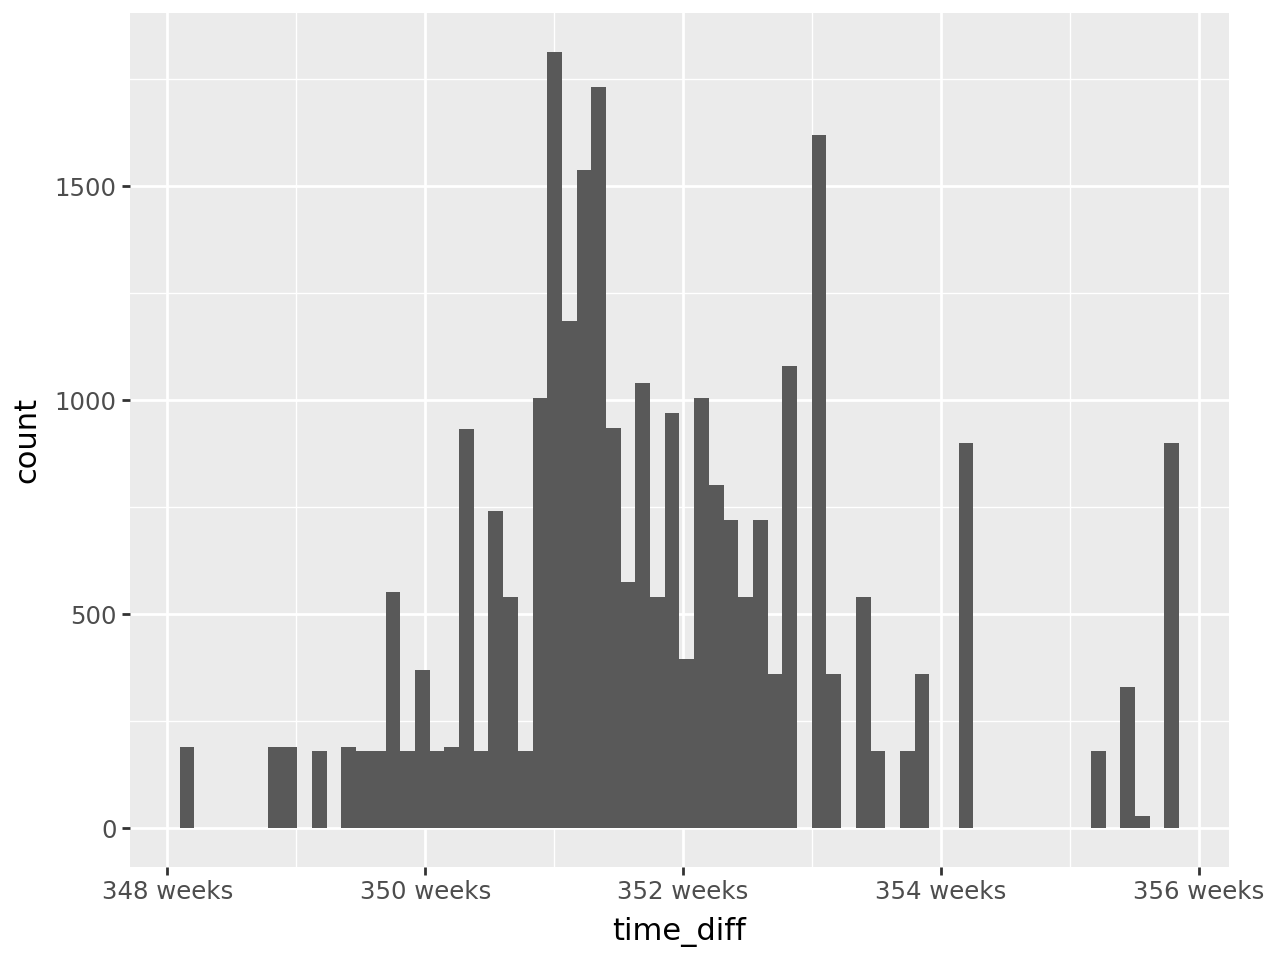

ExpressWay_2


C:\Users\katie\anaconda3\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 523'. Pick better value with 'binwidth'.


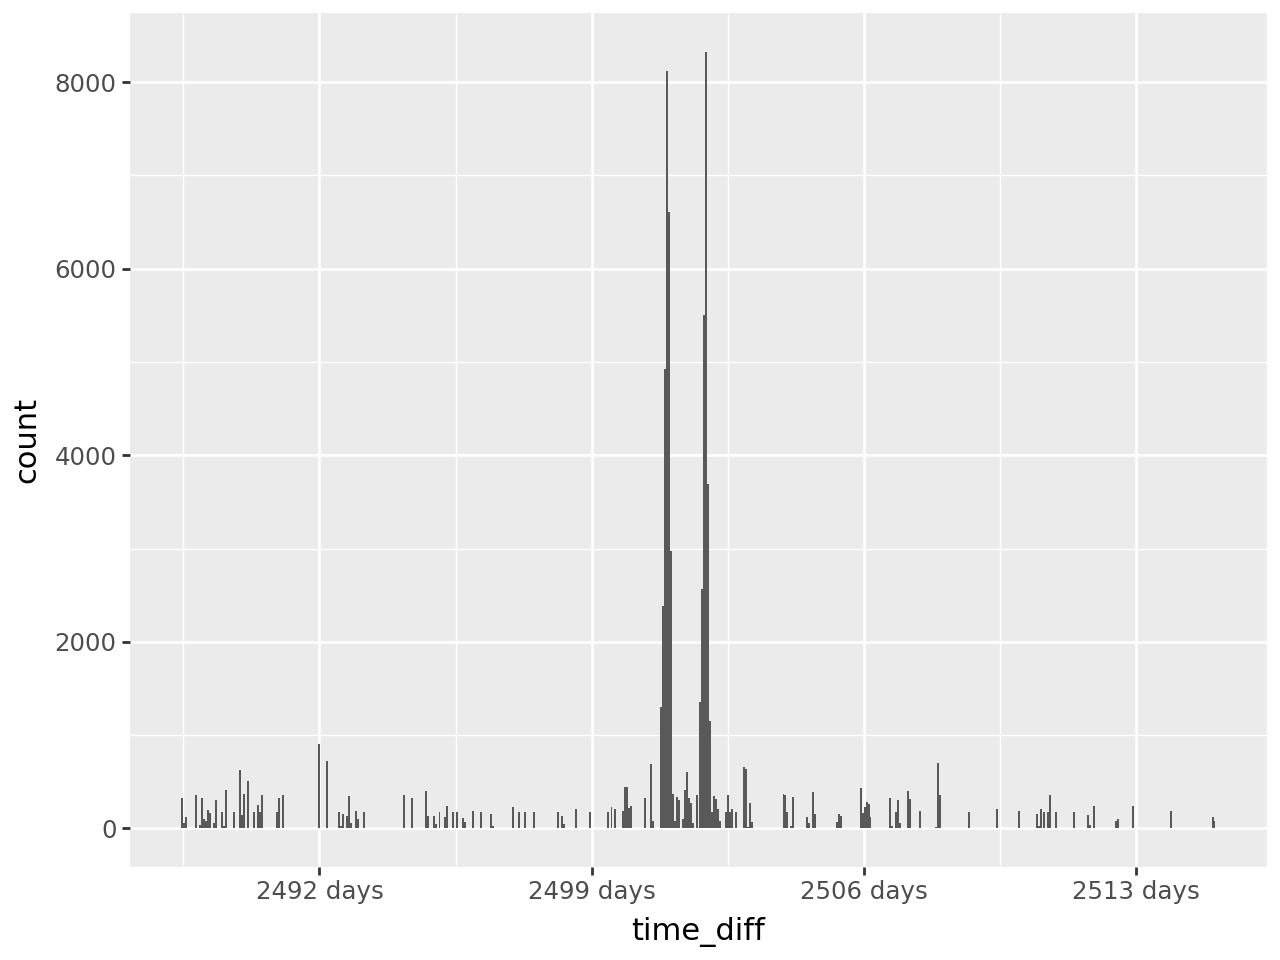

KilnWood


C:\Users\katie\anaconda3\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 226'. Pick better value with 'binwidth'.


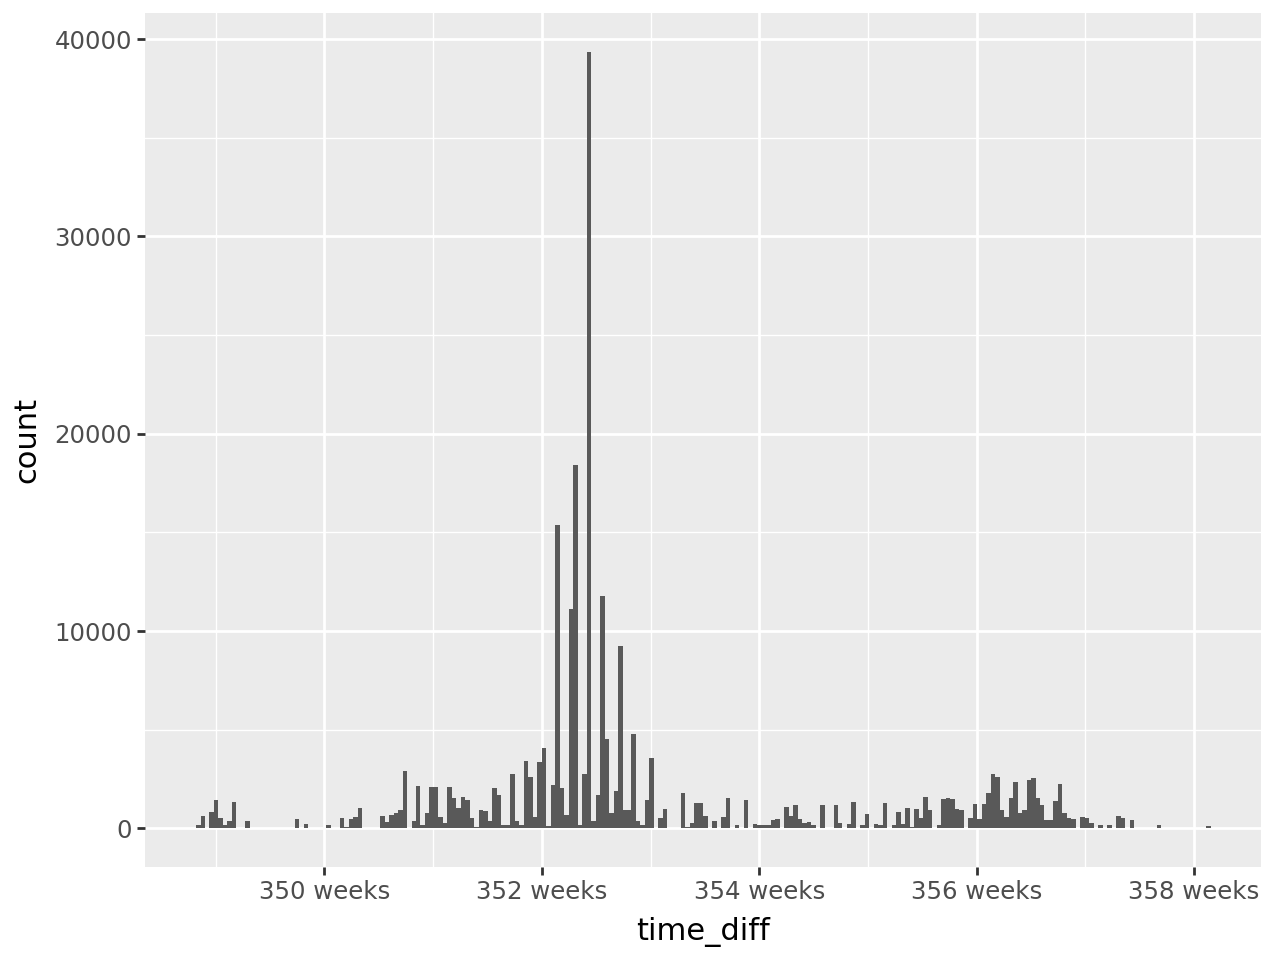

BatHouse_1


C:\Users\katie\anaconda3\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 245'. Pick better value with 'binwidth'.


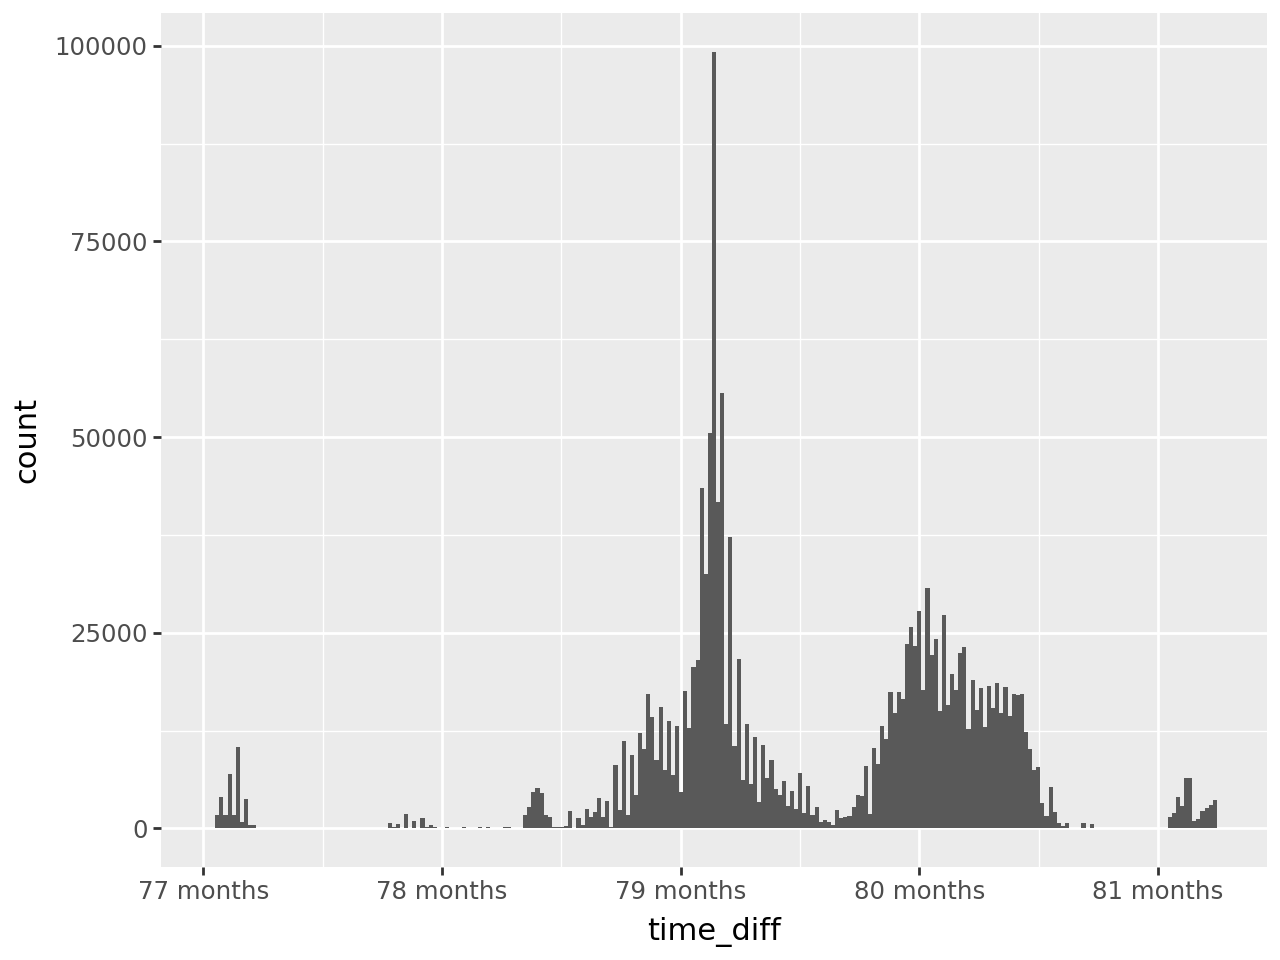

BatHouse_2


C:\Users\katie\anaconda3\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 145'. Pick better value with 'binwidth'.


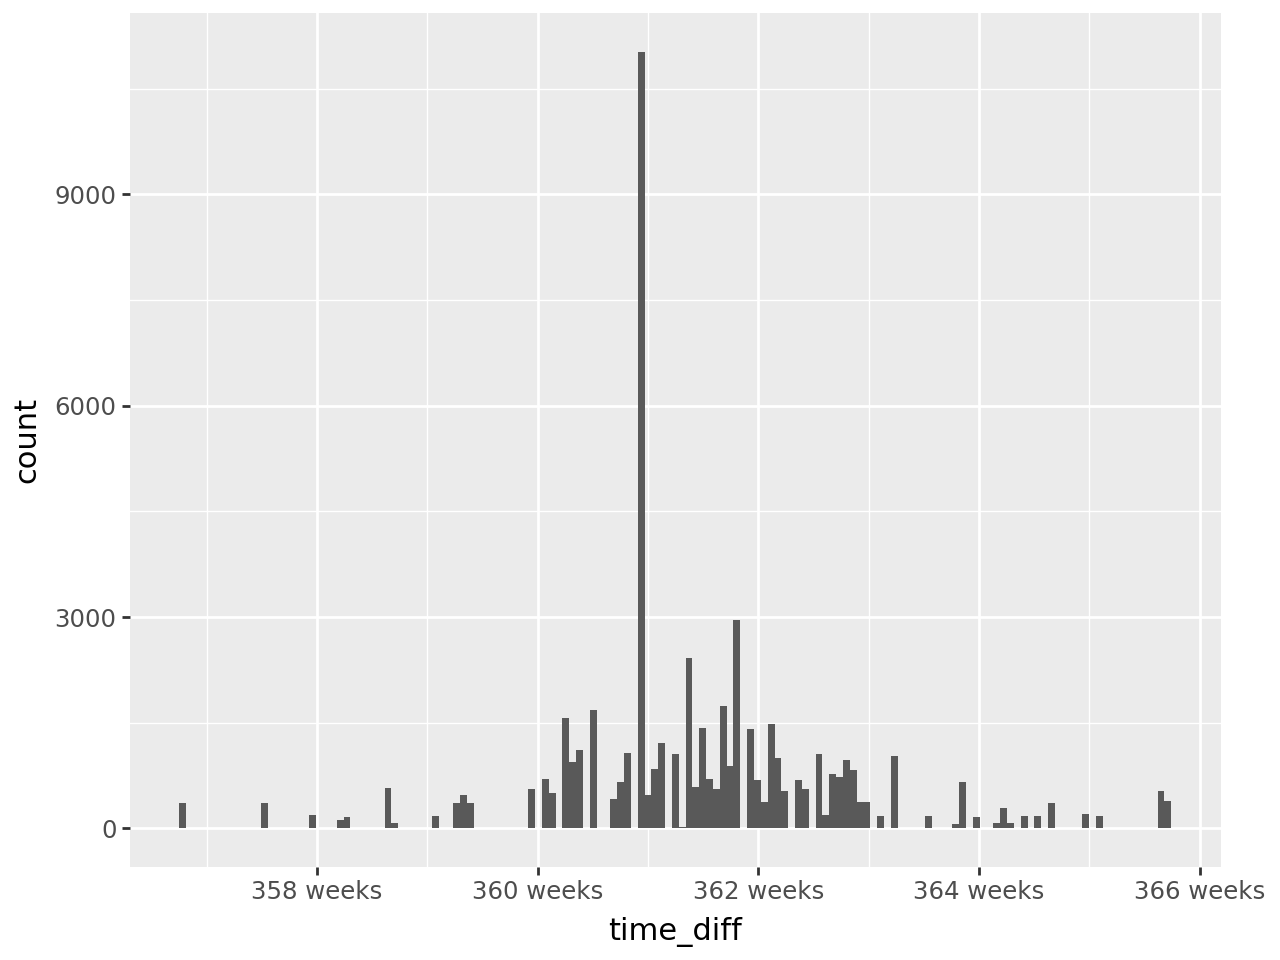

In [31]:
#create plots of each dataframe
for key, df in bathouse_all_results_table.items():
    print(key)
    p = ggplot(df, aes(x = "time_diff"))+ geom_histogram()
    p.show()

ExpressWay_1


C:\Users\katie\anaconda3\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 68'. Pick better value with 'binwidth'.


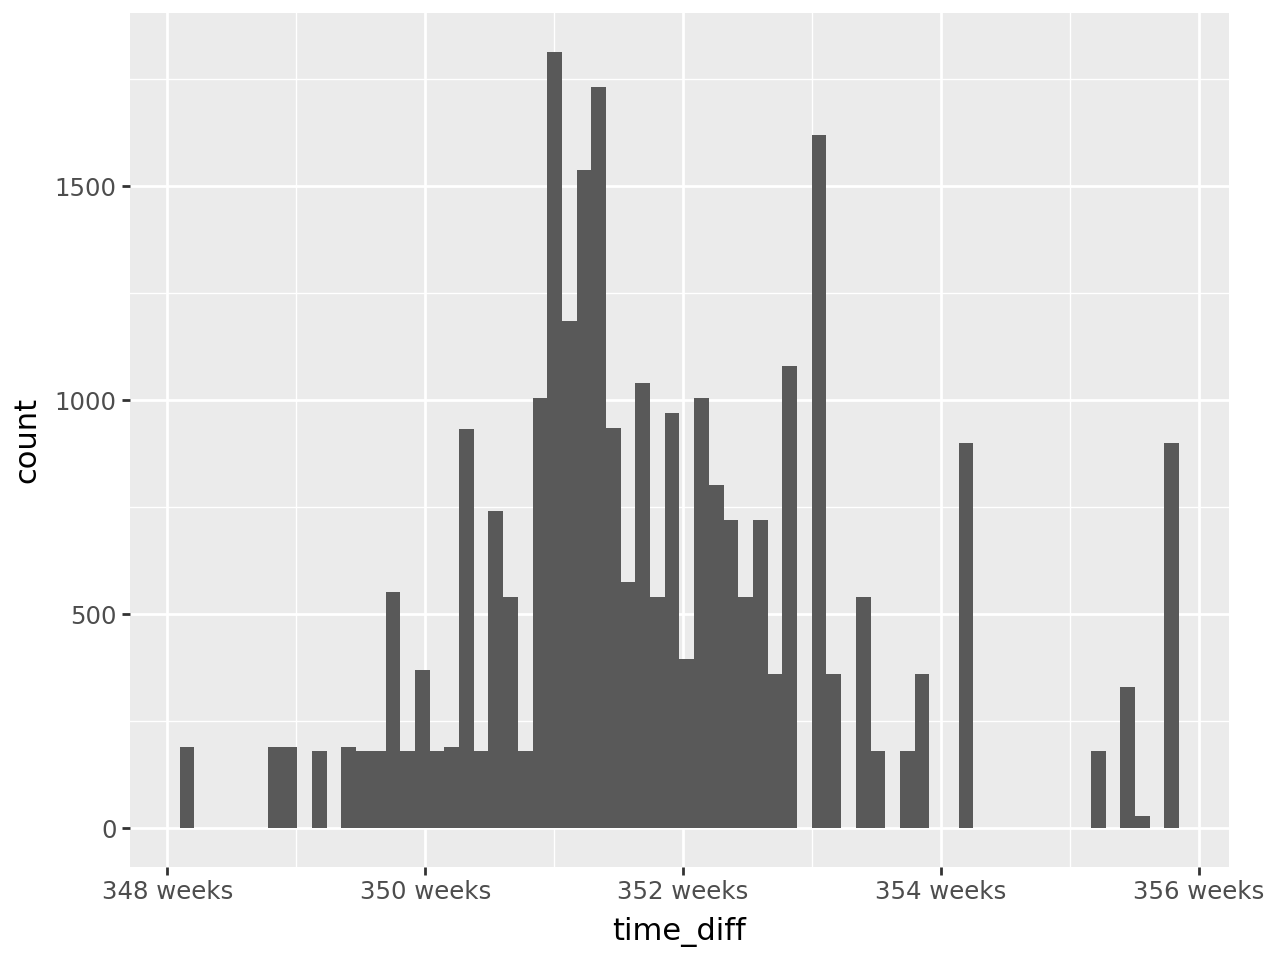

ExpressWay_2


C:\Users\katie\anaconda3\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 524'. Pick better value with 'binwidth'.


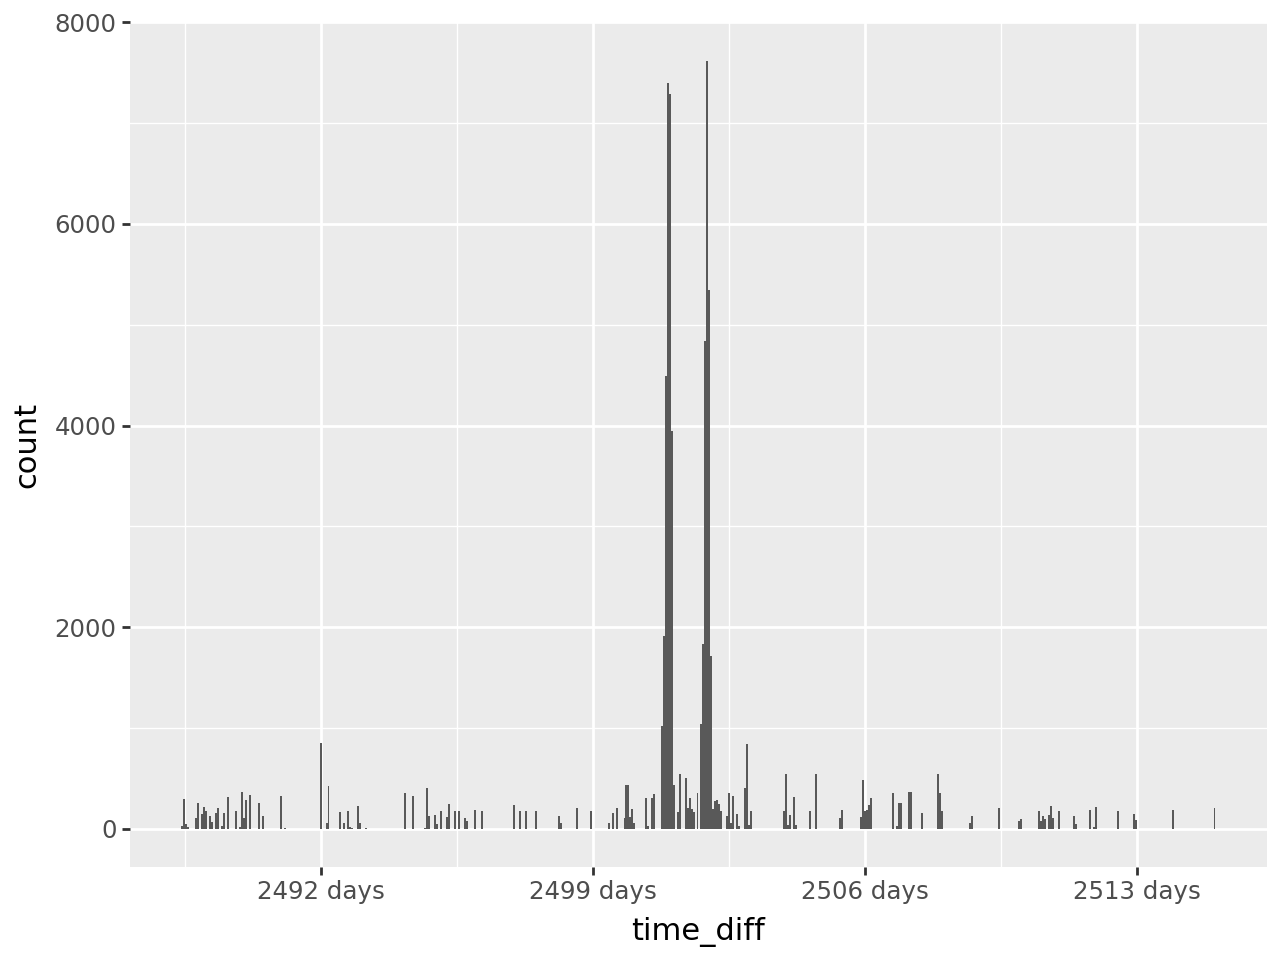

KilnWood


C:\Users\katie\anaconda3\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 222'. Pick better value with 'binwidth'.


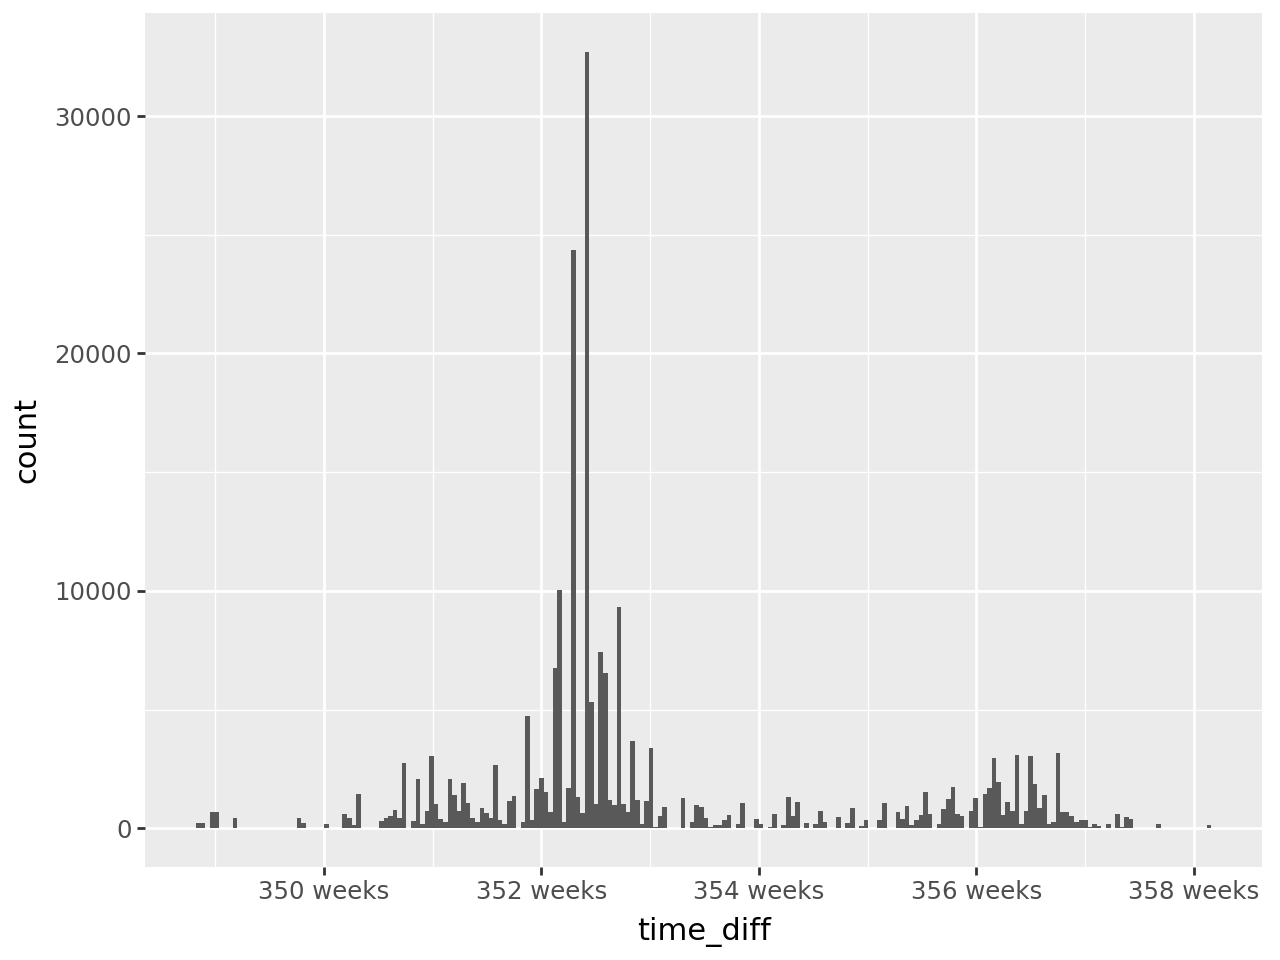

BatHouse_1


C:\Users\katie\anaconda3\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 222'. Pick better value with 'binwidth'.


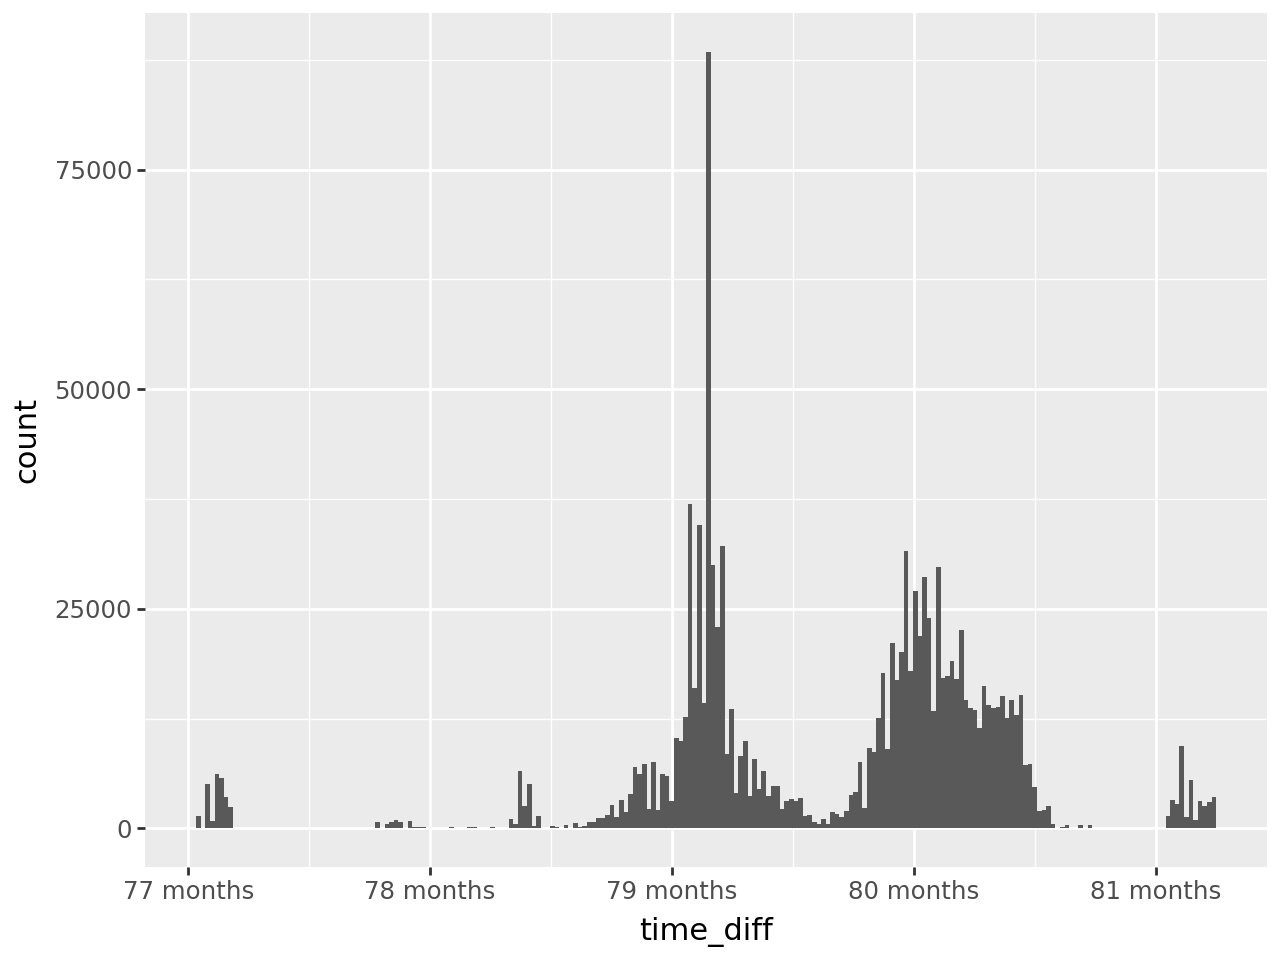

BatHouse_2


C:\Users\katie\anaconda3\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 131'. Pick better value with 'binwidth'.


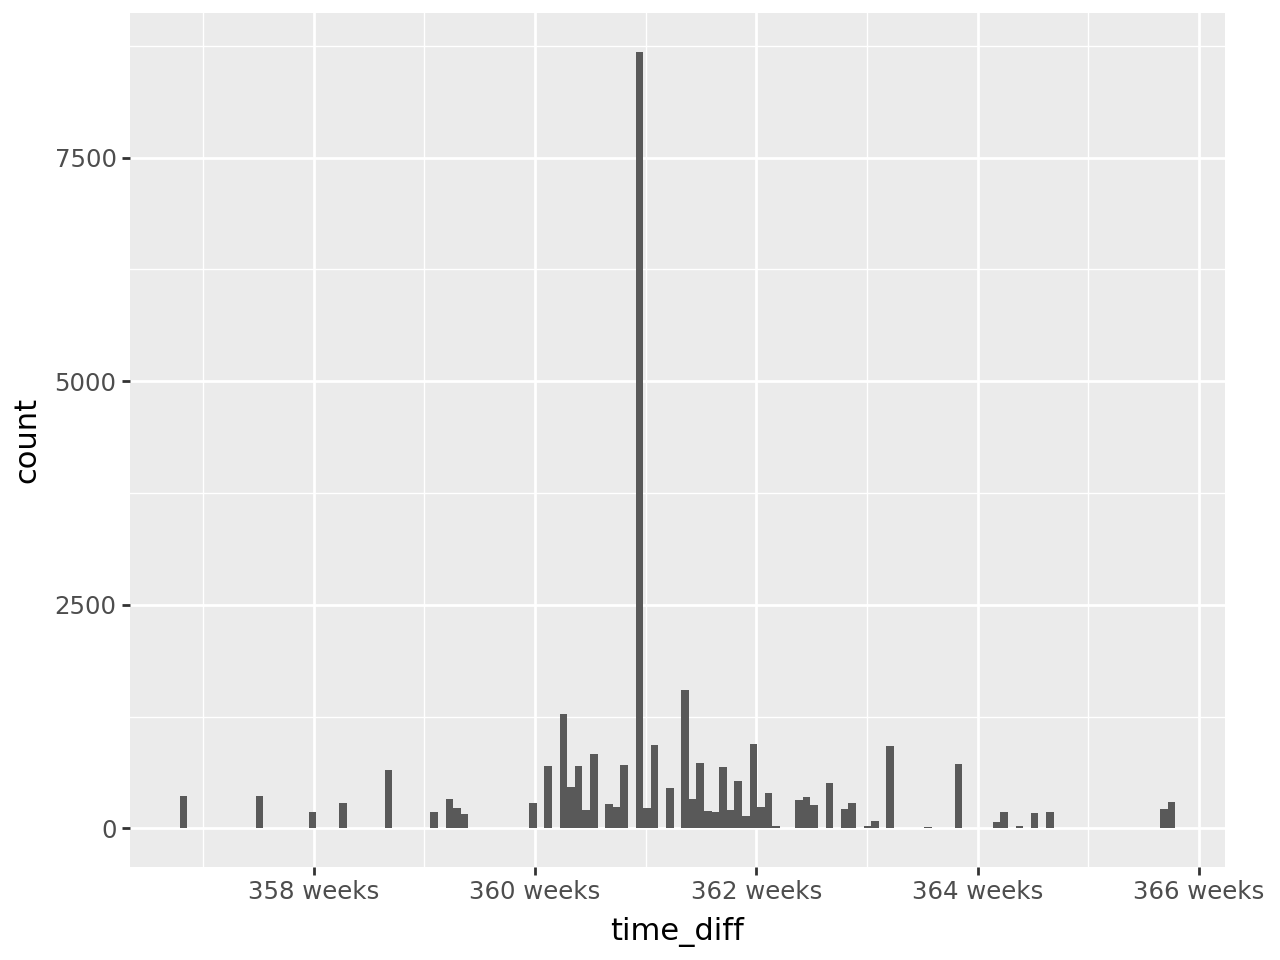

In [32]:
#create plots of each dataframe
for key, df in bathouse_low_kl_div_results_table.items():
    print(key)
    p = ggplot(df, aes(x = "time_diff"))+ geom_histogram()
    p.show()

ExpressWay_1


C:\Users\katie\anaconda3\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 68'. Pick better value with 'binwidth'.


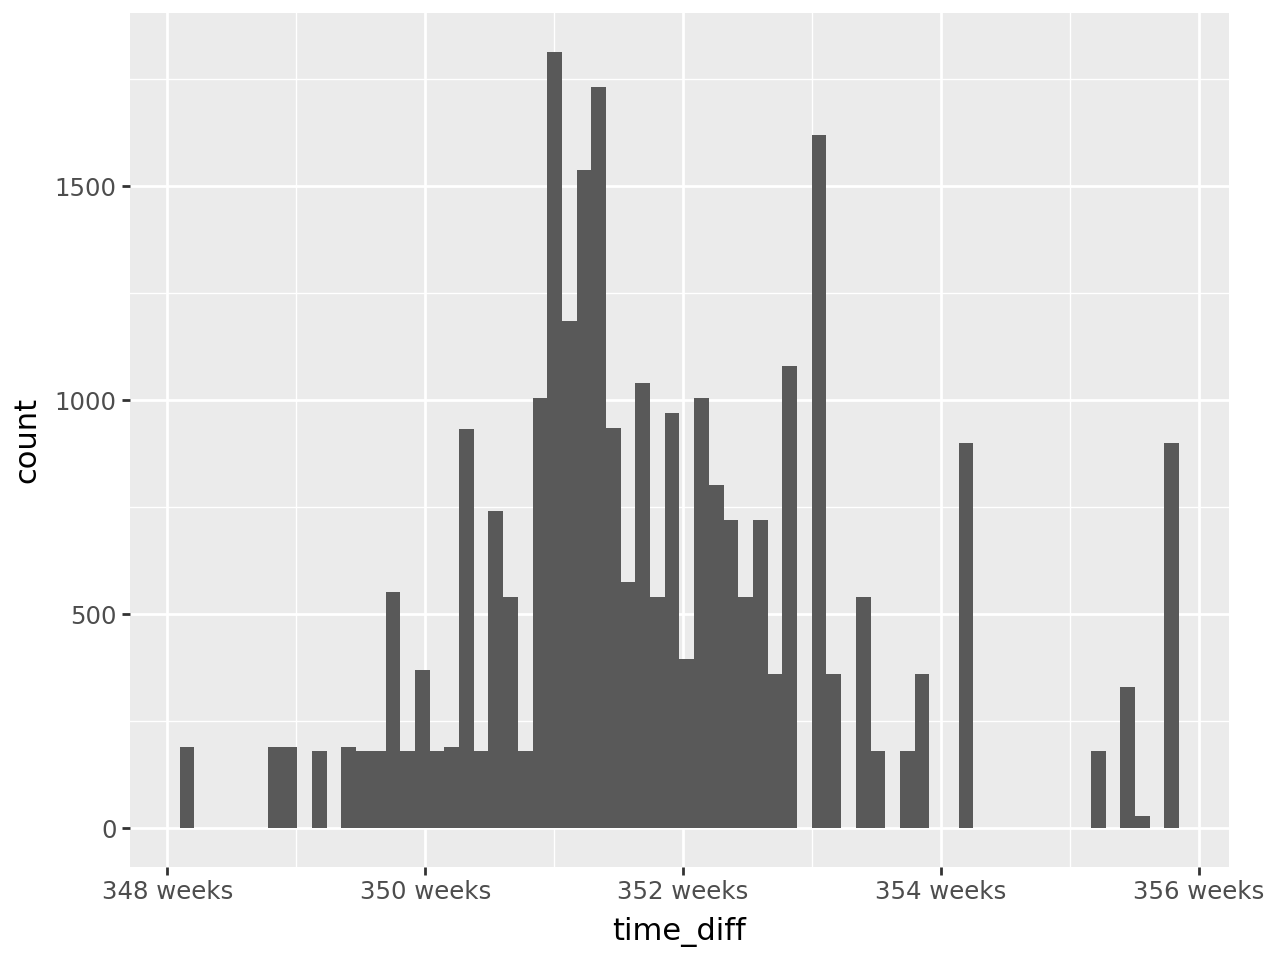

ExpressWay_2


C:\Users\katie\anaconda3\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 512'. Pick better value with 'binwidth'.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\positions\position.py:232: PlotnineWarning: position_stack requires non-overlapping x intervals


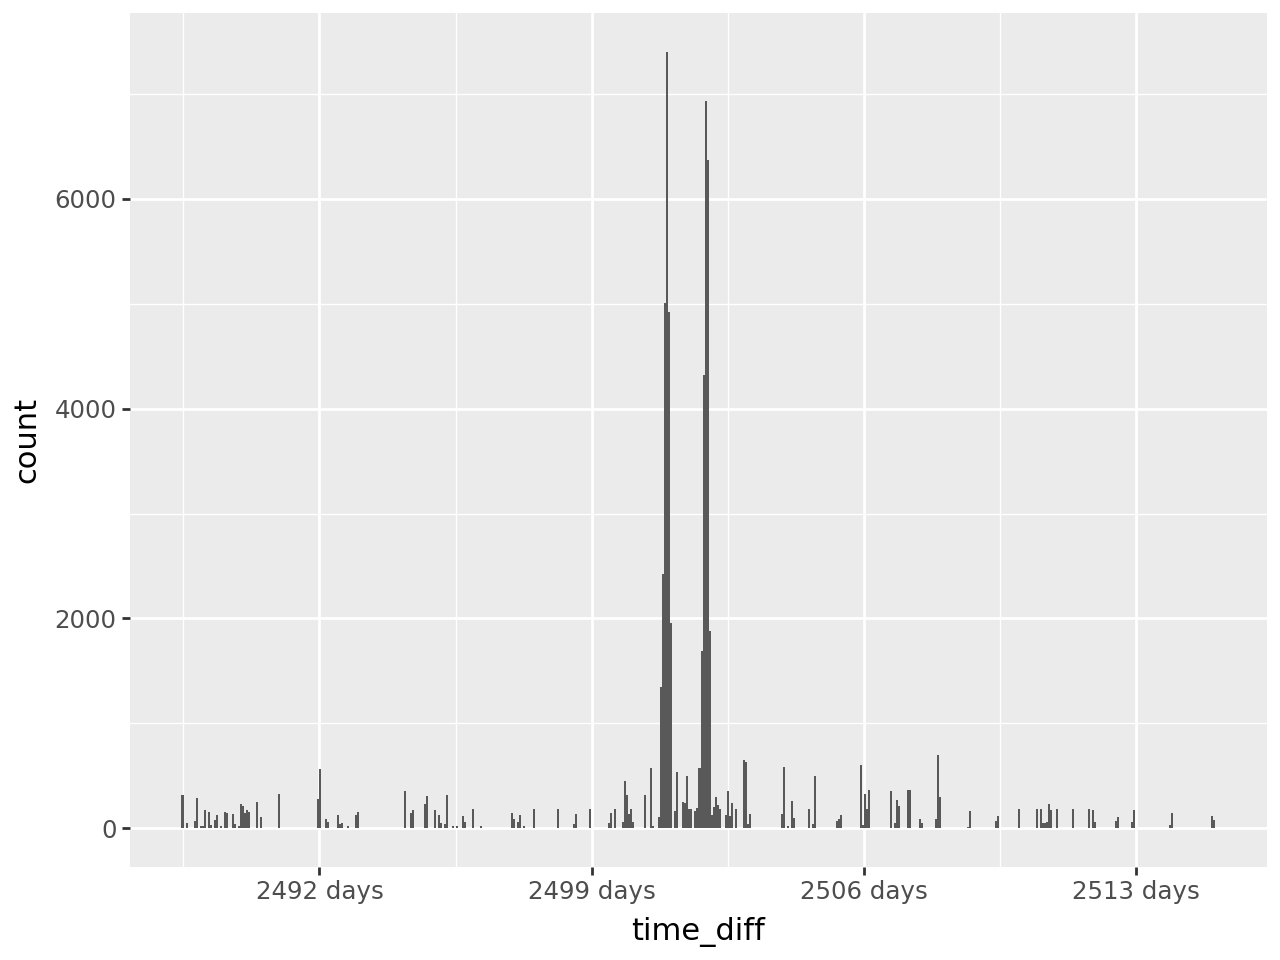

KilnWood


C:\Users\katie\anaconda3\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 120'. Pick better value with 'binwidth'.


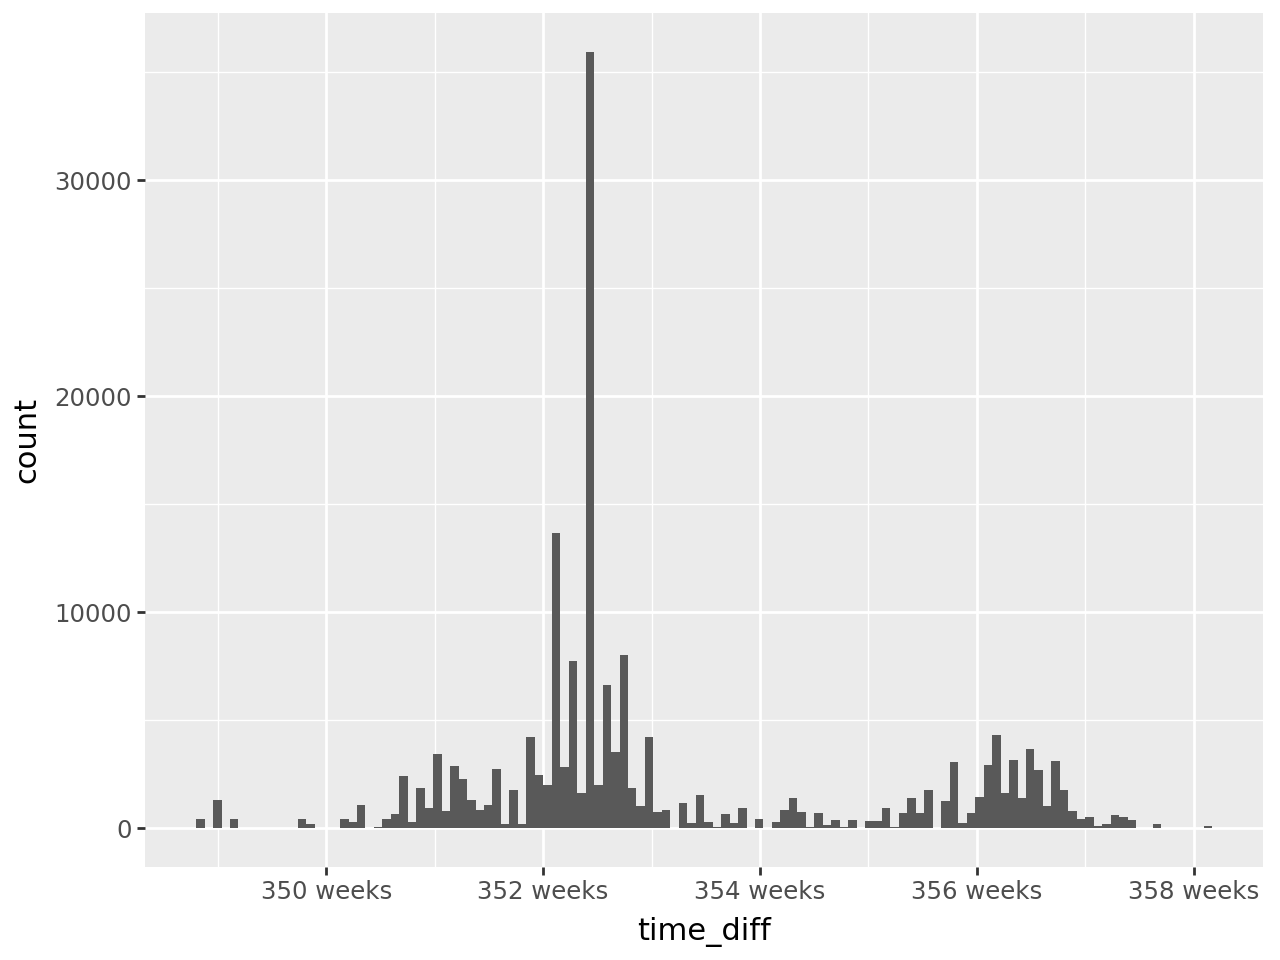

BatHouse_1


2024-07-09 11:06:58,630 - distributed.utils_perf - WARNING - full garbage collections took 14% CPU time recently (threshold: 10%)
2024-07-09 11:06:59,019 - distributed.utils_perf - WARNING - full garbage collections took 17% CPU time recently (threshold: 10%)
2024-07-09 11:06:59,412 - distributed.utils_perf - WARNING - full garbage collections took 43% CPU time recently (threshold: 10%)
2024-07-09 11:06:59,886 - distributed.utils_perf - WARNING - full garbage collections took 54% CPU time recently (threshold: 10%)
2024-07-09 11:07:00,293 - distributed.utils_perf - WARNING - full garbage collections took 55% CPU time recently (threshold: 10%)
2024-07-09 11:07:00,693 - distributed.utils_perf - WARNING - full garbage collections took 55% CPU time recently (threshold: 10%)
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 213'. Pick better value with 'binwidth'.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\position

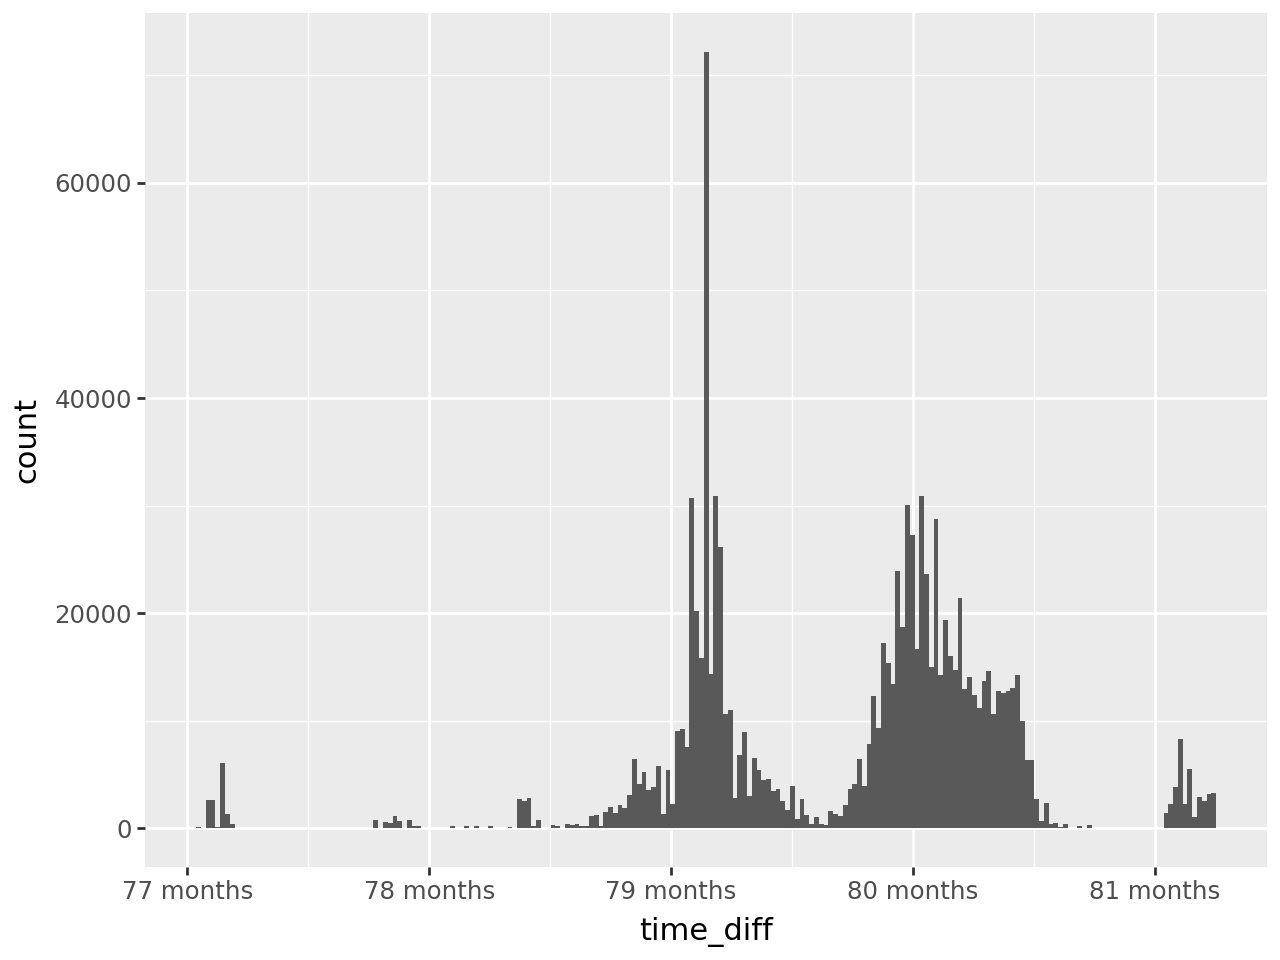

BatHouse_2


2024-07-09 11:07:03,043 - distributed.utils_perf - WARNING - full garbage collections took 53% CPU time recently (threshold: 10%)
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 138'. Pick better value with 'binwidth'.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\positions\position.py:232: PlotnineWarning: position_stack requires non-overlapping x intervals


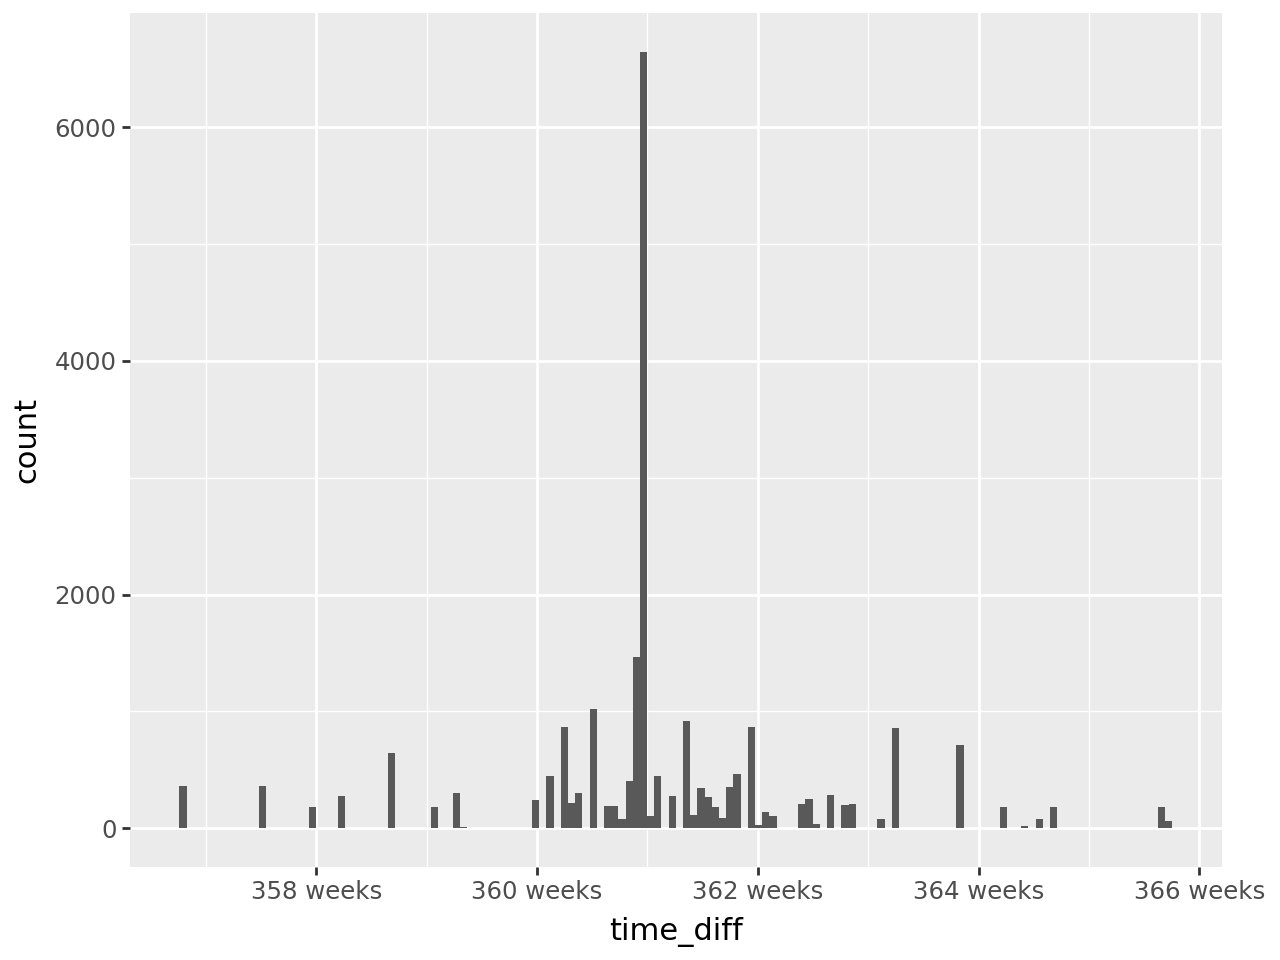

In [33]:
#create plots of each dataframe
for key, df in bathouse_very_low_kl_div_results_table.items():
    print(key)
    p = ggplot(df, aes(x = "time_diff"))+ geom_histogram()
    p.show()

ExpressWay_1


C:\Users\katie\anaconda3\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 68'. Pick better value with 'binwidth'.


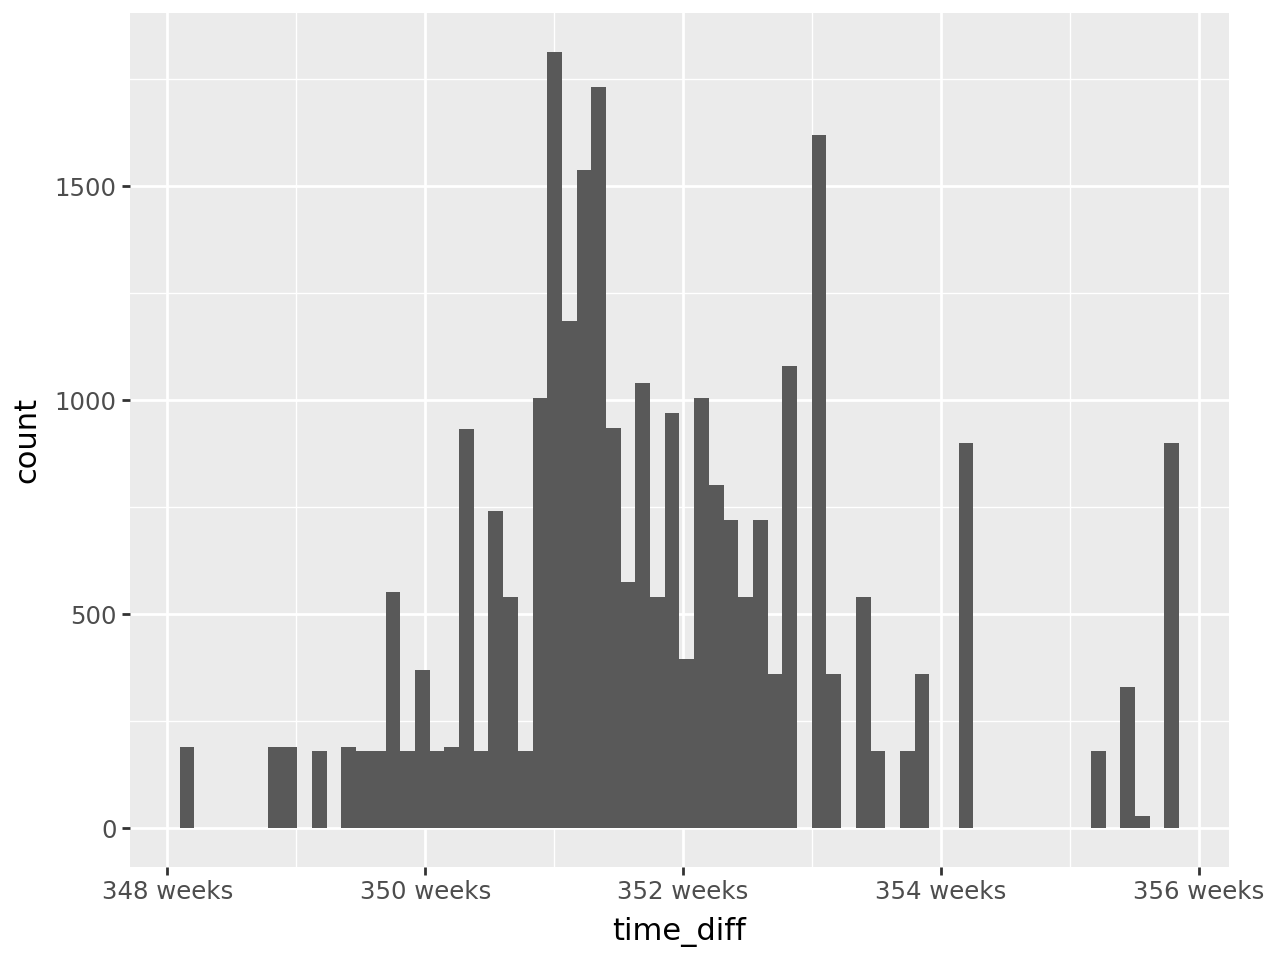

ExpressWay_2


C:\Users\katie\anaconda3\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 128'. Pick better value with 'binwidth'.


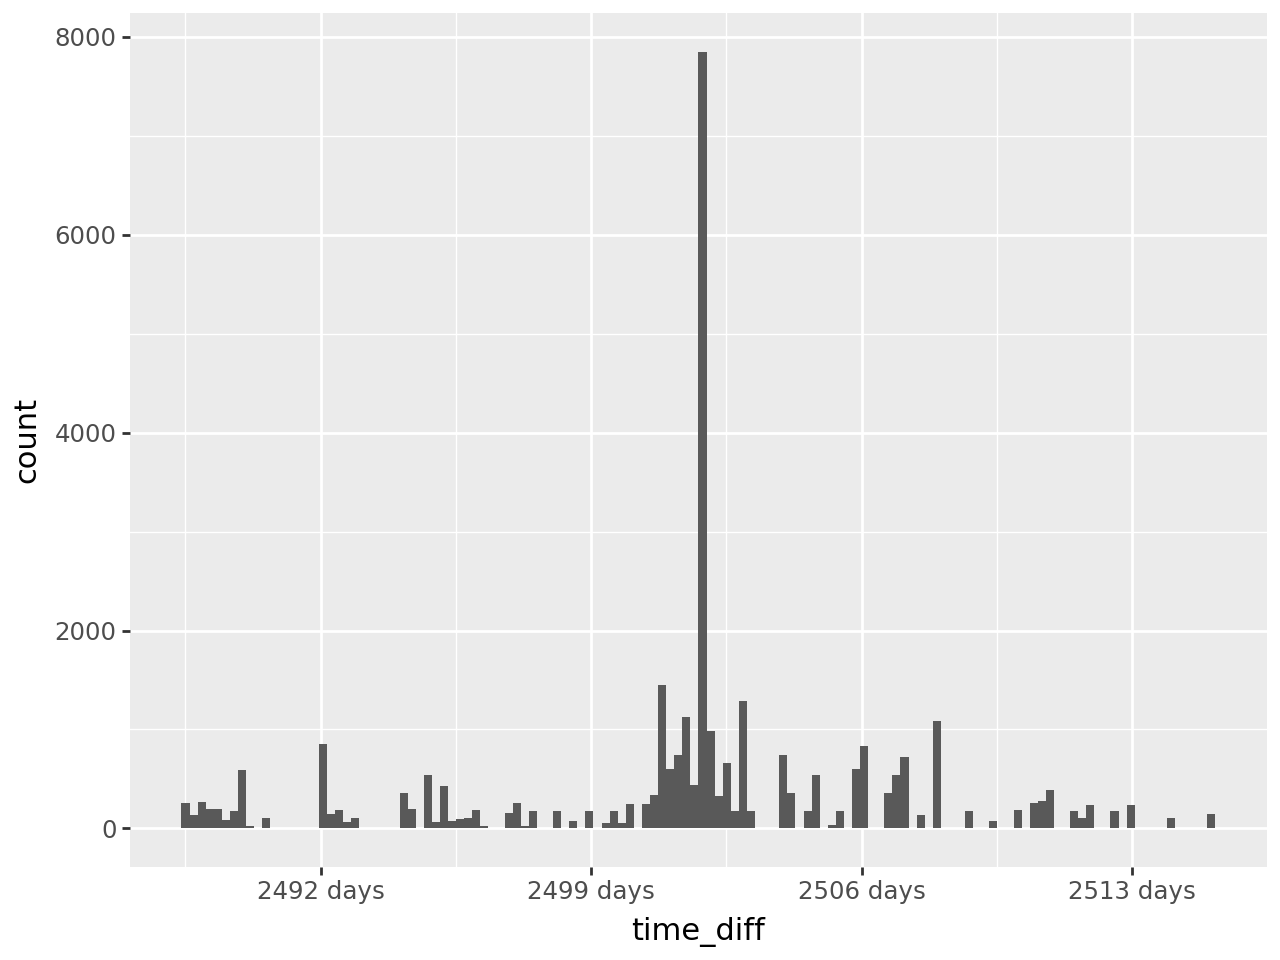

KilnWood


2024-07-09 11:07:28,228 - distributed.utils_perf - WARNING - full garbage collections took 52% CPU time recently (threshold: 10%)
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 72'. Pick better value with 'binwidth'.
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\positions\position.py:232: PlotnineWarning: position_stack requires non-overlapping x intervals


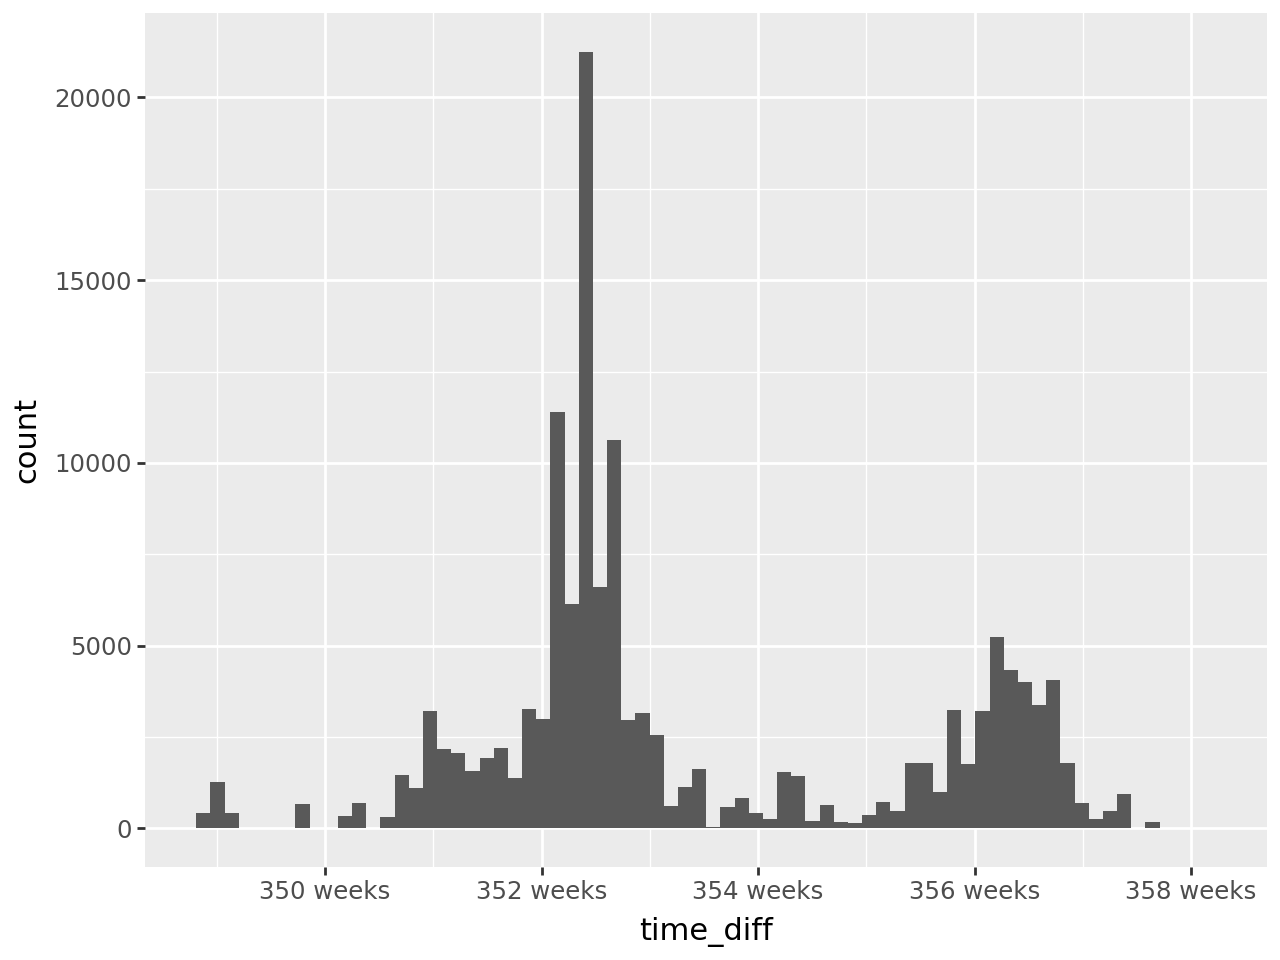

BatHouse_1


2024-07-09 11:07:29,217 - distributed.utils_perf - WARNING - full garbage collections took 52% CPU time recently (threshold: 10%)
2024-07-09 11:07:29,617 - distributed.utils_perf - WARNING - full garbage collections took 51% CPU time recently (threshold: 10%)
2024-07-09 11:07:30,015 - distributed.utils_perf - WARNING - full garbage collections took 51% CPU time recently (threshold: 10%)
2024-07-09 11:07:30,418 - distributed.utils_perf - WARNING - full garbage collections took 51% CPU time recently (threshold: 10%)
2024-07-09 11:07:30,829 - distributed.utils_perf - WARNING - full garbage collections took 52% CPU time recently (threshold: 10%)
C:\Users\katie\anaconda3\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 204'. Pick better value with 'binwidth'.
2024-07-09 11:07:32,645 - distributed.utils_perf - WARNING - full garbage collections took 49% CPU time recently (threshold: 10%)


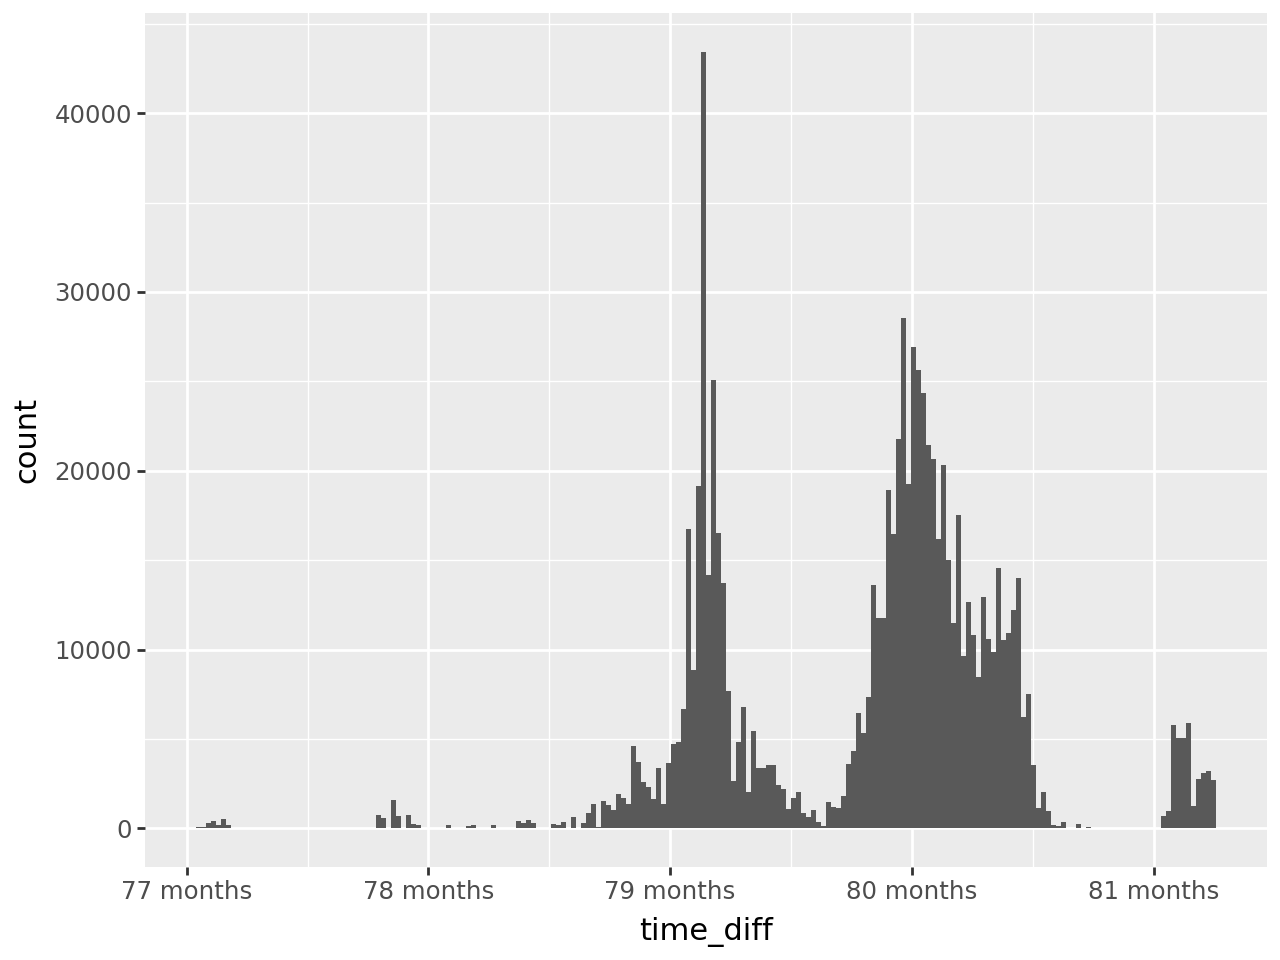

BatHouse_2


C:\Users\katie\anaconda3\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 192'. Pick better value with 'binwidth'.


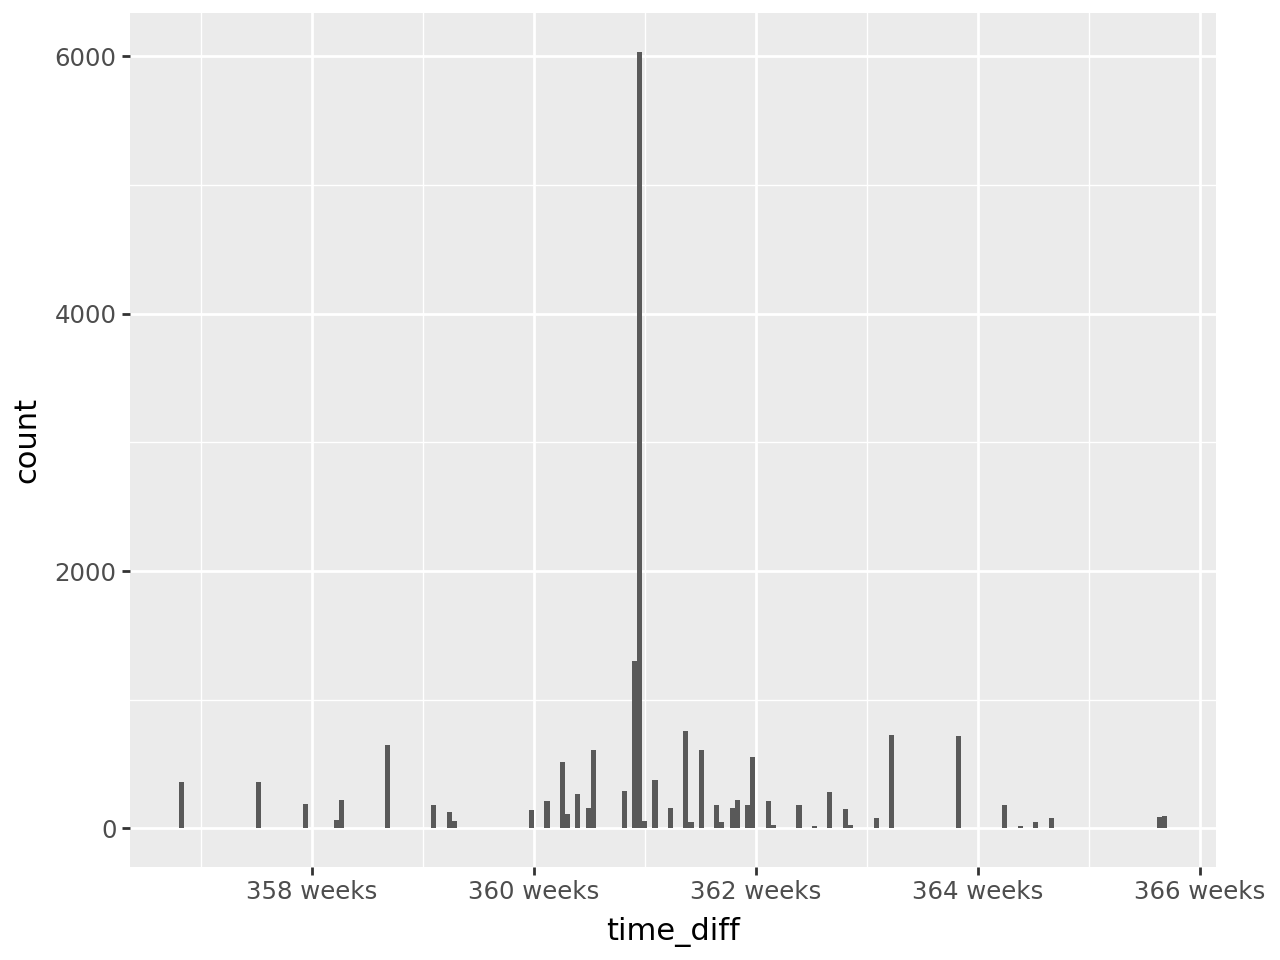

In [34]:
#create plots of each dataframe
for key, df in bathouse_zero_kl_div_results_table.items():
    print(key)
    p = ggplot(df, aes(x = "time_diff"))+ geom_histogram()
    p.show()

In [35]:
combined_modes = dict(list(bathouse_all_mode.items()) +
                  [(key, [bathouse_all_mode[key], bathouse_low_kl_div_mode[key]]) if key in bathouse_low_kl_div_mode else (key, bathouse_all_mode[key]) for key in bathouse_all_mode] +
                  [(key, bathouse_low_kl_div_mode[key]) for key in bathouse_low_kl_div_mode if key not in bathouse_all_mode])

In [36]:
combined_modes = {key: pd.concat(df).sort_values(by = 'time_diff') for key, df in combined_modes.items()}

In [37]:
#find first correction value
bathouse_simulated_real_time_diff = {key: df.iloc[0,0] - first_date for key, df in bathouse_anchors_raw.items()}
bathouse_simulated_real_time_diff

{'ExpressWay_1': Timedelta('2456 days 18:38:02'),
 'ExpressWay_2': Timedelta('2501 days 23:10:28'),
 'BatHouse_1': Timedelta('2453 days 13:47:53'),
 'BatHouse_2': Timedelta('2526 days 16:33:38'),
 'KilnWood': Timedelta('2467 days 01:17:22'),
 'Huxbear_Vineyard': Timedelta('2490 days 13:09:45'),
 'Chudleigh': Timedelta('2458 days 13:30:51')}

In [39]:
bathouse_all_mode_median = {key: df[['time_diff', 'kl_div']].agg(lambda x: x.mode().median()) for key, df in bathouse_all_results_table.items()}
bathouse_all_mode_median

{'ExpressWay_1': time_diff    2456 days 18:29:20
 kl_div                      0.0
 dtype: object,
 'ExpressWay_2': time_diff    2501 days 23:05:40
 kl_div                      0.0
 dtype: object,
 'KilnWood': time_diff    2467 days 01:19:30
 kl_div                      0.0
 dtype: object,
 'BatHouse_1': time_diff    2453 days 13:48:10
 kl_div                      0.0
 dtype: object,
 'BatHouse_2': time_diff    2526 days 16:34:20
 kl_div                      0.0
 dtype: object}

In [41]:
bathouse_low_kl_div_mode_median = {key: df[['time_diff', 'kl_div']].agg(lambda x: x.mode().median()) for key, df in bathouse_low_kl_div_results_table.items()}
bathouse_low_kl_div_mode_median

{'ExpressWay_1': time_diff    2456 days 18:29:20
 kl_div                      0.0
 dtype: object,
 'ExpressWay_2': time_diff    2501 days 23:05:40
 kl_div                      0.0
 dtype: object,
 'KilnWood': time_diff    2467 days 01:09:25
 kl_div                      0.0
 dtype: object,
 'BatHouse_1': time_diff    2453 days 13:48:10
 kl_div                      0.0
 dtype: object,
 'BatHouse_2': time_diff    2526 days 16:35:05
 kl_div                      0.0
 dtype: object}

In [43]:
bathouse_very_low_kl_div_mode_median = {key: df[['time_diff', 'kl_div']].agg(lambda x: x.mode().median()) for key, df in bathouse_very_low_kl_div_results_table.items()}
bathouse_very_low_kl_div_mode_median

{'ExpressWay_1': time_diff    2456 days 18:29:20
 kl_div                      0.0
 dtype: object,
 'ExpressWay_2': time_diff    2501 days 23:05:55
 kl_div                      0.0
 dtype: object,
 'KilnWood': time_diff    2467 days 01:19:40
 kl_div                      0.0
 dtype: object,
 'BatHouse_1': time_diff    2453 days 13:45:50
 kl_div                      0.0
 dtype: object,
 'BatHouse_2': time_diff    2526 days 16:35:30
 kl_div                      0.0
 dtype: object}

In [45]:
bathouse_zero_kl_div_mode_median = {key: df[['time_diff', 'kl_div']].agg(lambda x: x.mode().median()) for key, df in bathouse_zero_kl_div_results_table.items()}
bathouse_zero_kl_div_mode_median

{'ExpressWay_1': time_diff    2456 days 18:29:20
 kl_div                      0.0
 dtype: object,
 'ExpressWay_2': time_diff    2501 days 23:04:45
 kl_div                      0.0
 dtype: object,
 'KilnWood': time_diff    2467 days 01:00:55
 kl_div                      0.0
 dtype: object,
 'BatHouse_1': time_diff    2453 days 13:48:05
 kl_div                      0.0
 dtype: object,
 'BatHouse_2': time_diff    2526 days 16:35:30
 kl_div                      0.0
 dtype: object}

In [49]:
# create dictionary of result tables
bathouse_grouped_summary_stats = {
    "bathouse_all_summary": bathouse_all_summary_stats,
    "bathouse_all_mode": bathouse_all_mode,
    "bathouse_all_mode_median": bathouse_all_mode_median,
    "bathouse_low_kl_div_summary": bathouse_low_kl_div_summary_stats,
    "bathouse_low_kl_div_mode": bathouse_low_kl_div_mode,
    "bathouse_low_kl_div_mode_median": bathouse_low_kl_div_mode_median,
    "bathouse_very_low_kl_div_summary": bathouse_very_low_kl_div_summary_stats,
    "bathouse_very_low_kl_div_mode": bathouse_very_low_kl_div_mode,
    "bathouse_very_low_kl_div_mode_median": bathouse_very_low_kl_div_mode_median,
    "bathouse_zero_kl_div_summary": bathouse_zero_kl_div_summary_stats,
    "bathouse_zero_kl_div_mode": bathouse_zero_kl_div_mode,
    "bathouse_zero_kl_div_mode_median": bathouse_zero_kl_div_mode_median
}

## Export data

In [ ]:
#write pickle file of results
with open(f'{output_dir}/bathouse_grouped_summary_stats_window_size_030.pickle', 'wb') as handle:
        pickle.dump(bathouse_grouped_summary_stats, handle, protocol=pickle.HIGHEST_PROTOCOL)

2024-07-09 20:54:40,313 - distributed.scheduler - WARNING - Worker failed to heartbeat within 300 seconds. Closing: <WorkerState 'tcp://127.0.0.1:58785', name: 3, status: running, memory: 0, processing: 0>
2024-07-09 20:54:40,328 - distributed.scheduler - WARNING - Worker failed to heartbeat within 300 seconds. Closing: <WorkerState 'tcp://127.0.0.1:58791', name: 0, status: running, memory: 0, processing: 0>
2024-07-09 20:54:40,341 - distributed.scheduler - WARNING - Received heartbeat from unregistered worker 'tcp://127.0.0.1:58785'.
2024-07-09 20:54:40,348 - distributed.scheduler - WARNING - Received heartbeat from unregistered worker 'tcp://127.0.0.1:58791'.
